# ZFO benchmark atlas

**One direction. Four local models. Twelve tests of when step selection is useful.**

This notebook studies SGD, Adam, and Muon with constant learning rates and four
ZFO selectors. It is an exploratory CPU experiment using the reusable library,
not a claim of state-of-the-art performance or a reproduction of the LLM paper.

Each experiment follows the same sequence: a short explanation, a result table,
then learning-rate scans and convergence plots. Tables retain failures.
Full protocol: [benchmarks/README.md](../benchmarks/README.md).

The saved outputs are real executed runs. To recompute optimization, run
`python -m benchmarks.suite --output benchmarks/results/new_run --seeds 3`
from the `wrapper/` directory and update `RESULTS` below. Re-executing this notebook
only regenerates analysis from the specified saved evidence.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists() and (p / 'benchmarks').exists())
sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown, Image
from io import BytesIO
import matplotlib.pyplot as plt
from benchmarks.report import load_results, task_tables, task_figure, comparison_table
RESULTS = ROOT / 'benchmarks/results/reference'
data = load_results(RESULTS)
manifest = data['manifest']
display({k: manifest[k] for k in ['status', 'steps', 'tuning_seeds', 'report_seeds', 'lr_grids', 'beta', 'epsilon', 'interior_search', 'torch', 'dtype', 'tuning_runs', 'report_runs', 'elapsed_seconds']})

{'status': 'complete',
 'steps': 100,
 'tuning_seeds': [100, 101, 102],
 'report_seeds': [200, 201, 202],
 'lr_grids': {'SGD': {'flat': [1e-05,
    3.1622776601683795e-05,
    0.0001,
    0.00031622776601683794,
    0.001,
    0.0031622776601683794,
    0.01,
    0.03162277660168379,
    0.1,
    0.31622776601683794,
    1.0,
    3.1622776601683795,
    10.0],
   'taylor2': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
   'taylor3': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
   'pade2': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
   'pade3': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]},
  'Adam': {'flat': [1e-05,
    3.1622776601683795e-05,
    0.0001,
    0.00031622776601683794,
    0.001,
    0.0031622776601683794,
    0.01,
    0.03162277660168379,
    0.1,
    0.31622776601683794,
    1.0,
    3.1622776601683795,
    10.0],
   'taylor2': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
   'taylor3': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0],
   'pade2': [1e-05, 0.0001, 0.001,

## Which steps can Padé3 select?

This run explicitly uses **interior_search=true**. Padé3 compares endpoints and valid interior stationary points of its fitted rational model. The existing pole and degeneracy safeguards still apply. This differs from the RLVR auto convention.
Selecting the best fitted-model candidate does not guarantee the best actual
loss along the interval. The diagnostic column **Model interiors (%)** counts
interior selections made without fallback.

The original atlas used auto by mistake; its saved results remain under
`benchmarks/results/endpoint_reference`. The first interior-enabled run with
seven rates for every method is preserved in `benchmarks/results/coarse_reference`.
The current reference keeps that candidate policy and refines only the flat
baseline LR grid to 13 rates. Seeds, beta, epsilon, and budgets are unchanged.
Interior search is applied to every task rather than selected based on
favorable test results.

## Read the comparisons fairly

Rates are selected separately for every optimizer/selector using mean final
validation loss on tuning seeds, then frozen before the reporting seeds. Test
examples are untouched during tuning and step selection. Classical problems
use separate seed-defined instances instead of held-out datasets.

All methods get the same update count. **Flat baselines get 13 learning rates;
each ZFO method gets seven.** Flat adds a geometric midpoint between each pair
of the original rates, preserving the same endpoints (1e-5 and 10). Beta stays
fixed at 3. This gives flat 1.86× as many candidates; it is not an equal tuning
compute comparison. ZFO usually uses three forwards and one backward per
update; flat uses one of each. The
**equal-work** table stops at the same `F + 2B` budget using these selected rates.
This is an explicit cost proxy, not measured FLOPs, and these rates were not
retuned for the shorter compute horizon. Timing excludes monitoring, but includes
the adapter's state-snapshot overhead. Three seeds and one CPU run are modest evidence.
Runs that diverge at or before the work budget are incomplete in the equal-work
table; their last finite checkpoint is not treated as a completed budget result.
Later failures can still have a valid earlier equal-work checkpoint.

Thin plot lines show individual seeds; bold lines show means. Table spreads are
sample standard deviations, not confidence intervals. Crosses in scans mean at
least one tuning seed diverged. An edge rate needs a wider scan before
interpreting superiority. Mean curves require all reporting seeds at a checkpoint.
Individual trajectories end at their own last finite checkpoint. Values below
1e-12 are floored only in log plots.

Muon uses native 2D tensors; classical vectors are represented as (1,d) matrices,
so those cases have degenerate matrix geometry. Network bias terms are augmented
columns. This is distinct from the original LLM Muon/AdamW hybrid.

## Isotropic quadratic

**Classical experiment.** A well-scaled convex control. A tuned constant step already works well; extra probes can be pure overhead.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [2]:
outcomes, diagnostics = task_tables(data, 'sphere')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,1.0,0 ± 0,0 ± 0,0,0,False
1,SGD,Taylor2,10.0,9.07e-16 ± 1.3e-15,9.07e-16 ± 1.3e-15,0,0,True
2,SGD,Taylor3,1.0,1.121e-39 ± 9.7e-40,1.121e-39 ± 9.7e-40,0,0,False
3,SGD,Padé2,0.1,2.974e-13 ± 4.4e-14,2.974e-13 ± 4.4e-14,0,0,False
4,SGD,Padé3,0.1,2.974e-13 ± 4.4e-14,2.974e-13 ± 4.4e-14,0,0,False
5,Adam,Flat LR,1.0,0.0002386 ± 0.00014,0.0002386 ± 0.00014,0,0,False
6,Adam,Taylor2,1.0,8.488e-05 ± 1.6e-05,0.006771 ± 0.002,0,0,False
7,Adam,Taylor3,10.0,8.488e-05 ± 1.6e-05,0.006771 ± 0.002,0,0,True
8,Adam,Padé2,0.1,0.0001598 ± 5.7e-05,0.021 ± 0.0091,0,0,False
9,Adam,Padé3,0.1,0.0001103 ± 2.7e-05,0.01254 ± 0.0057,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.02311 ± 0.0035,100.0000,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,9.07e-16 ± 1.3e-15,0.0264 ± 0.0021,300.0000,100.0,99.0000,0.0000,1.0000,True
2,SGD,Taylor3,1.121e-39 ± 9.7e-40,0.02049 ± 0.0025,234.6667,100.0,98.0000,98.0000,2.0000,True
3,SGD,Padé2,2.974e-13 ± 4.4e-14,0.02356 ± 0.0022,300.0000,100.0,55.0000,55.0000,0.0000,True
4,SGD,Padé3,2.974e-13 ± 4.4e-14,0.02068 ± 0.00037,300.0000,100.0,55.0000,78.0000,0.0000,True
5,Adam,Flat LR,0 ± 0,0.008915 ± 0.00045,100.0000,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-0.0001537 ± 0.00013,0.02723 ± 0.00092,300.0000,100.0,0.0000,0.0000,100.0000,True
7,Adam,Taylor3,-0.0001537 ± 0.00013,0.0264 ± 0.00082,300.0000,100.0,0.0000,0.0000,100.0000,True
8,Adam,Padé2,-7.886e-05 ± 0.00015,0.02758 ± 0.00019,300.0000,100.0,2.6667,0.0000,0.0000,True
9,Adam,Padé3,-0.0001284 ± 0.00013,0.03034 ± 0.00089,300.0000,100.0,0.0000,7.6667,51.3333,True


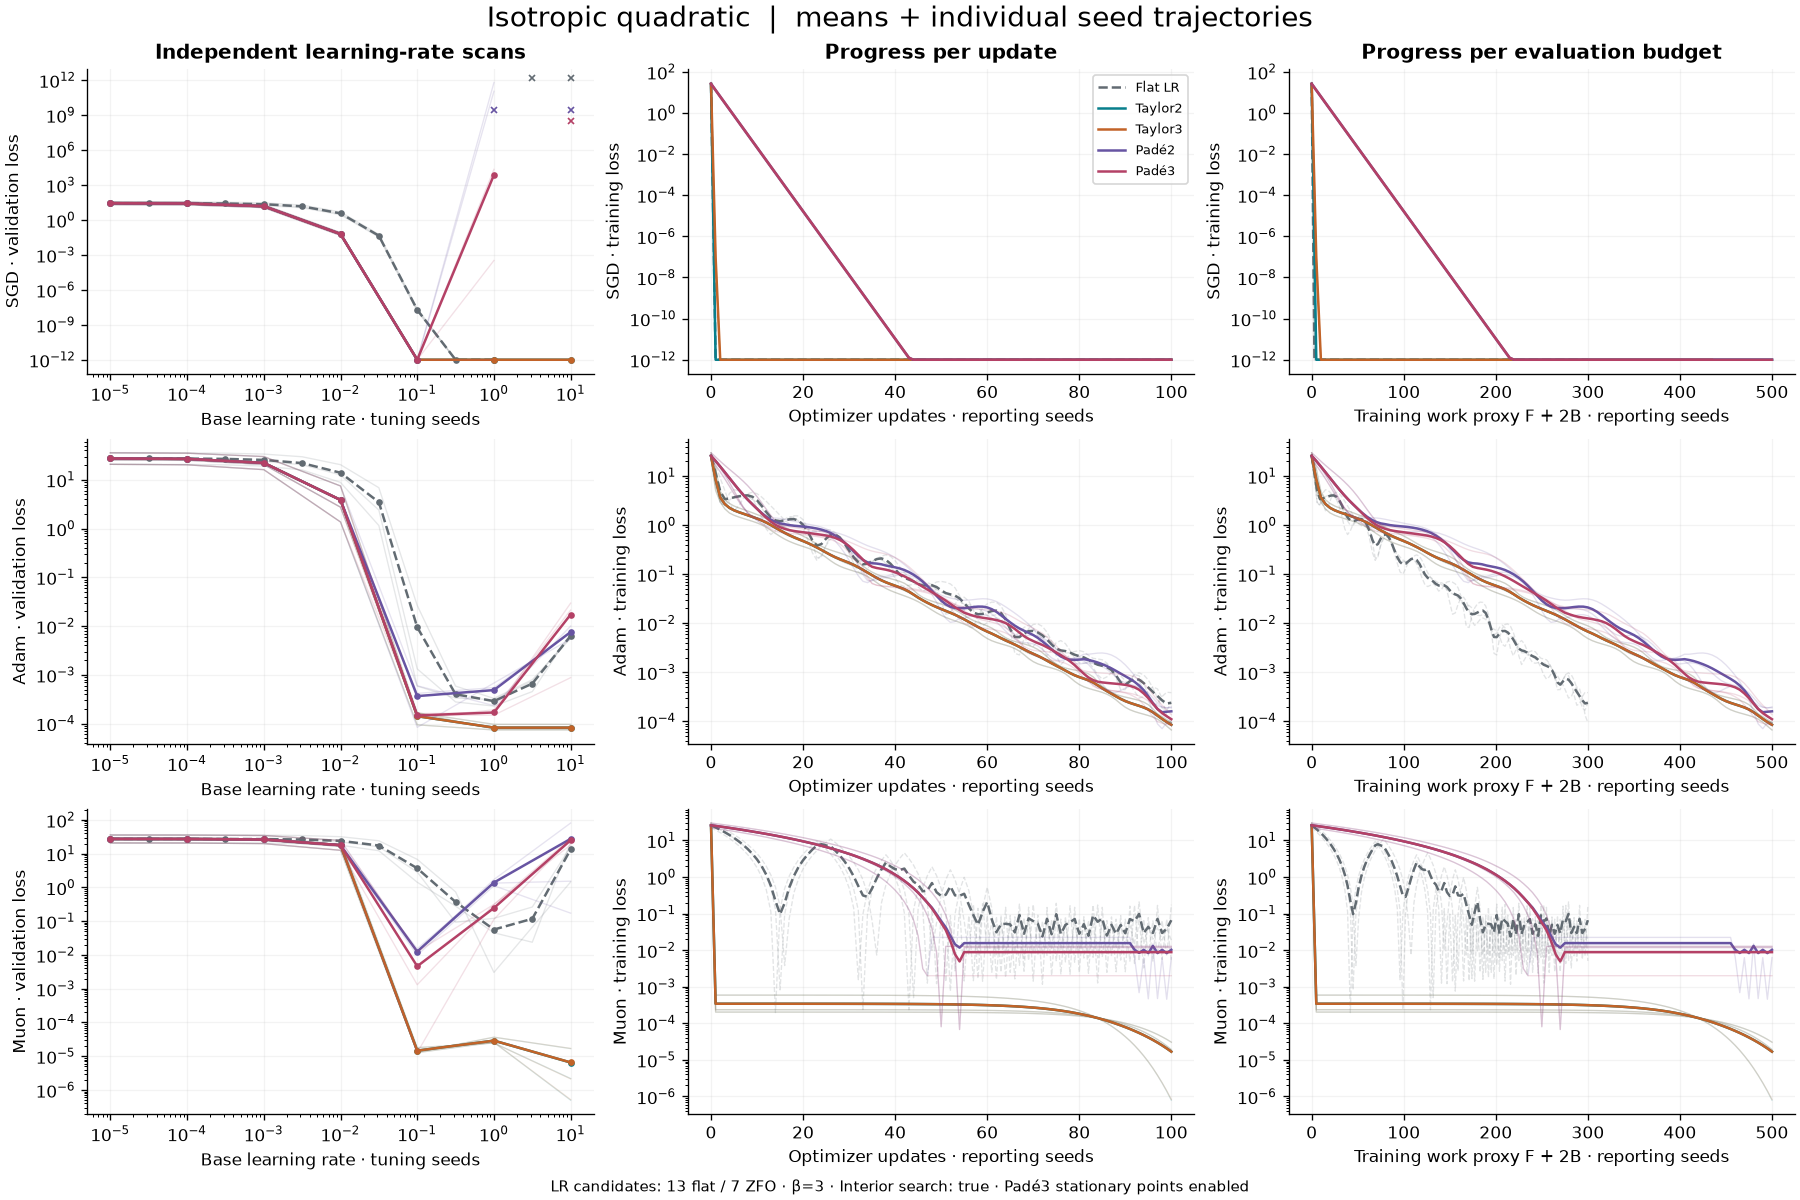

In [3]:
fig = task_figure(data, 'sphere')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Ill-conditioned least squares

**Classical experiment.** A rotated linear system with condition number 10,000 in its Hessian. Tests scale sensitivity without nonconvexity.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [4]:
outcomes, diagnostics = task_tables(data, 'ill_conditioned')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,1.000000,0.00678 ± 0.0062,0.00678 ± 0.0062,0,0,False
1,SGD,Taylor2,1.000000,0.003425 ± 0.003,0.005751 ± 0.0052,0,0,False
2,SGD,Taylor3,1.000000,0.003425 ± 0.003,0.005751 ± 0.0052,0,0,False
3,SGD,Padé2,0.100000,0.01535 ± 0.013,0.02347 ± 0.018,0,0,False
4,SGD,Padé3,1.000000,0.002975 ± 0.0027,0.005002 ± 0.0047,0,0,False
5,Adam,Flat LR,1.000000,0.0004878 ± 0.0004,0.0004878 ± 0.0004,0,0,False
6,Adam,Taylor2,10.000000,0.0002075 ± 0.00023,0.00211 ± 0.0012,0,0,True
7,Adam,Taylor3,1.000000,0.0001968 ± 0.00021,0.00211 ± 0.0012,0,0,False
8,Adam,Padé2,1.000000,0.0008167 ± 0.00055,0.002675 ± 0.0013,0,0,False
9,Adam,Padé3,1.000000,0.0009488 ± 0.00081,0.004973 ± 0.0018,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.01239 ± 0.0015,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,-0.003355 ± 0.0032,0.03198 ± 0.0053,300.0,100.0,0.0000,0.0000,99.3333,True
2,SGD,Taylor3,-0.003355 ± 0.0032,0.03649 ± 0.0066,300.0,100.0,0.0000,0.0000,99.3333,True
3,SGD,Padé2,0.008565 ± 0.0073,0.02491 ± 0.00095,300.0,100.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,-0.003805 ± 0.0036,0.02396 ± 0.0022,300.0,100.0,0.0000,1.6667,62.0000,True
5,Adam,Flat LR,0 ± 0,0.01076 ± 0.0004,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-0.0002803 ± 0.00018,0.04146 ± 0.005,300.0,100.0,0.0000,0.0000,100.0000,True
7,Adam,Taylor3,-0.0002911 ± 0.0002,0.03208 ± 0.0036,300.0,100.0,0.0000,0.0000,98.3333,True
8,Adam,Padé2,0.0003289 ± 0.00055,0.0388 ± 0.016,300.0,100.0,7.6667,0.0000,0.0000,True
9,Adam,Padé3,0.000461 ± 0.001,0.03081 ± 0.0017,300.0,100.0,2.0000,61.6667,24.0000,True


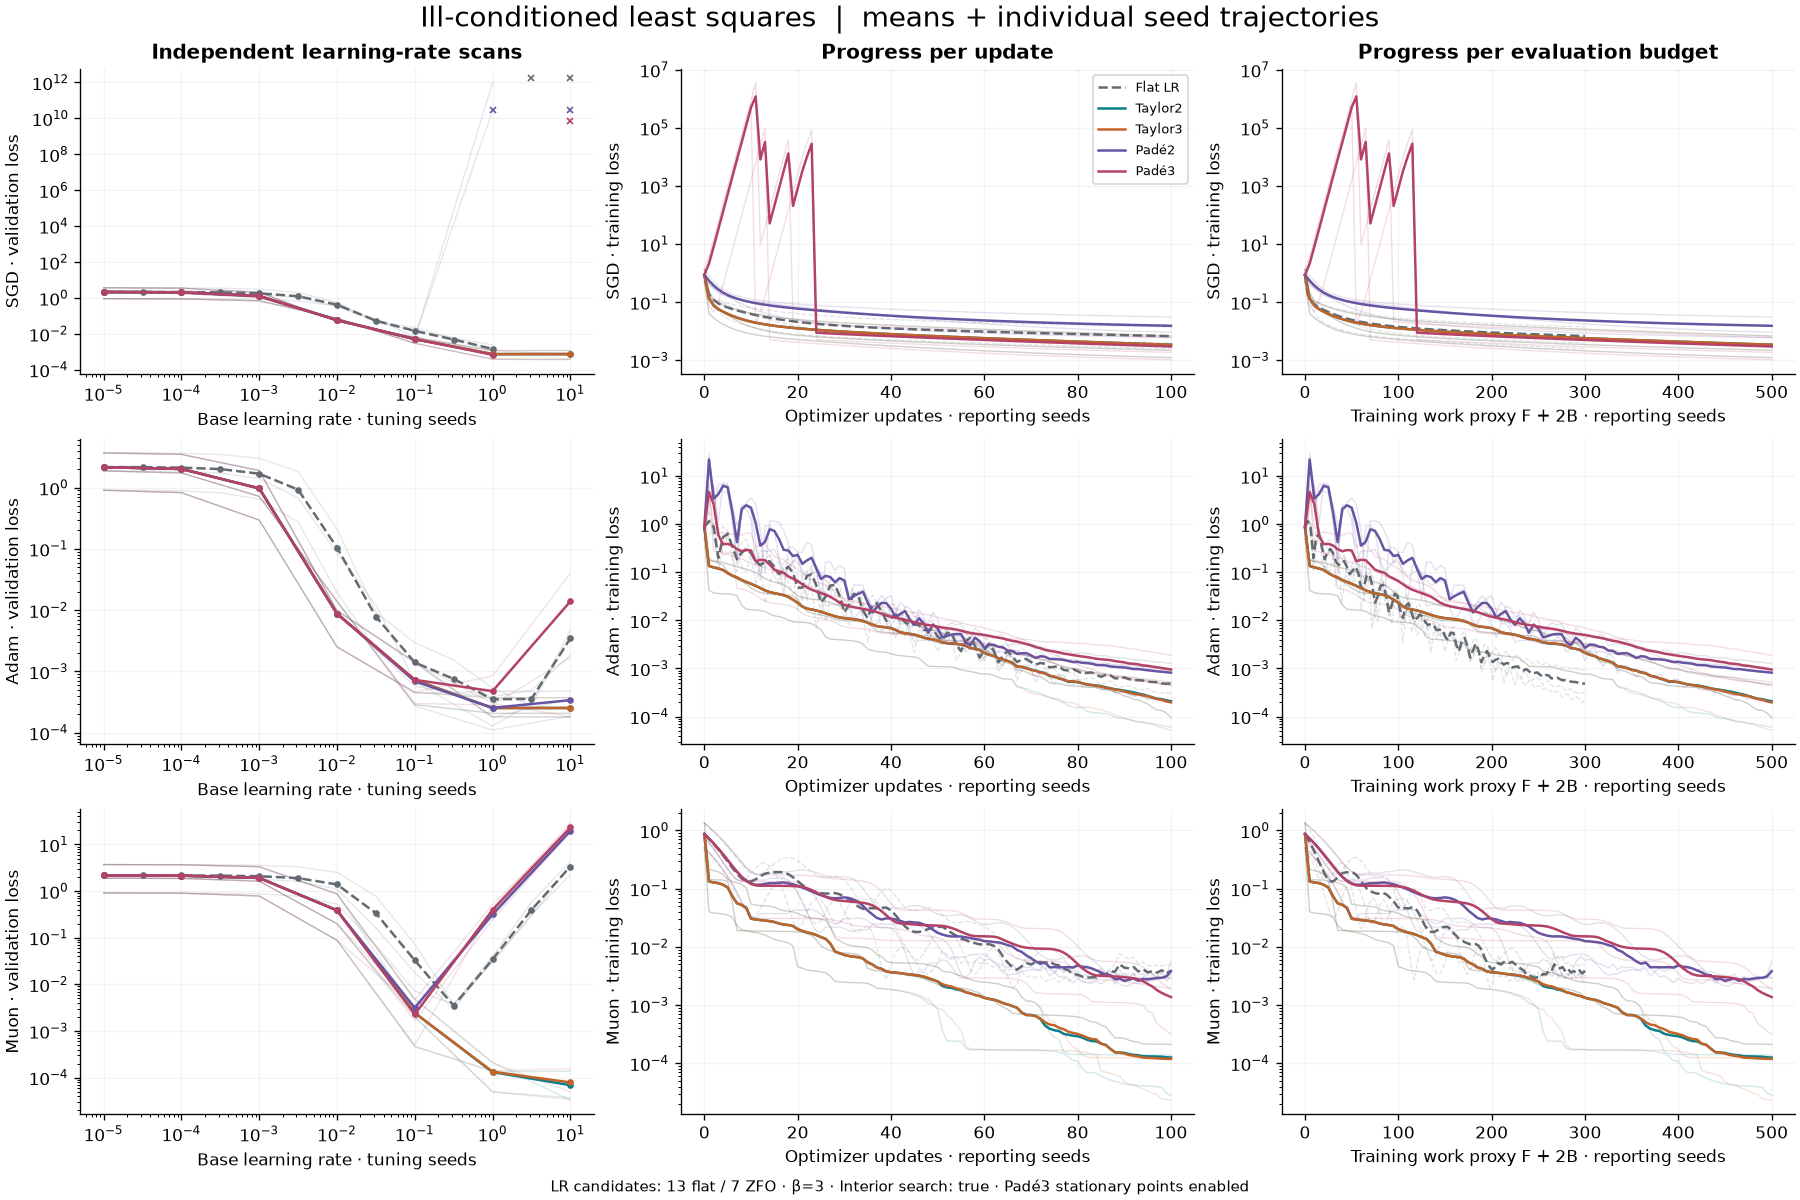

In [5]:
fig = task_figure(data, 'ill_conditioned')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Exponential curve fitting

**Classical experiment.** Fit amplitude, decay, and offset from a poor initial guess. Rapid curvature changes challenge a local polynomial or rational model.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [6]:
outcomes, diagnostics = task_tables(data, 'nonlinear_lse')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,1.000000,0.007018 ± 0.0059,0.007018 ± 0.0059,0,0,False
1,SGD,Taylor2,10.000000,0.01959 ± 0.0023,0.02109 ± 0.0032,0,0,True
2,SGD,Taylor3,0.100000,0.02014 ± 0.00028,0.0265 ± 0.0083,0,0,False
3,SGD,Padé2,0.100000,0.02014 ± 0.00028,0.0265 ± 0.0083,0,0,False
4,SGD,Padé3,0.100000,0.01995 ± 0.00018,0.02151 ± 0.00033,0,0,False
5,Adam,Flat LR,0.316228,0.0001187 ± 8.8e-06,0.0001187 ± 8.8e-06,0,0,False
6,Adam,Taylor2,1.000000,0.01363 ± 0.00033,0.01599 ± 0.0017,0,0,False
7,Adam,Taylor3,0.100000,0.01668 ± 0.00025,0.01923 ± 0.0014,0,0,False
8,Adam,Padé2,0.100000,0.01199 ± 0.01,0.05946 ± 0.049,0,0,False
9,Adam,Padé3,0.100000,0.01667 ± 0.00024,0.0192 ± 0.0014,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.01109 ± 0.0002,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,0.01257 ± 0.0039,0.02607 ± 0.00057,300.0,100.0,0.0000,0.0000,99.6667,True
2,SGD,Taylor3,0.01312 ± 0.0058,0.02732 ± 0.00061,300.0,100.0,0.0000,0.0000,0.0000,True
3,SGD,Padé2,0.01312 ± 0.0058,0.02727 ± 0.00066,300.0,100.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,0.01293 ± 0.0061,0.03358 ± 0.0083,300.0,100.0,0.0000,1.0000,0.6667,True
5,Adam,Flat LR,0 ± 0,0.01302 ± 0.00028,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,0.01351 ± 0.00034,0.03285 ± 0.0019,300.0,100.0,3.6667,0.0000,84.0000,True
7,Adam,Taylor3,0.01657 ± 0.00025,0.03541 ± 0.00072,300.0,100.0,0.0000,0.0000,39.0000,True
8,Adam,Padé2,0.01187 ± 0.01,0.03328 ± 0.00058,300.0,100.0,19.0000,0.0000,0.0000,True
9,Adam,Padé3,0.01655 ± 0.00024,0.04182 ± 0.0032,300.0,100.0,0.0000,2.3333,39.0000,True


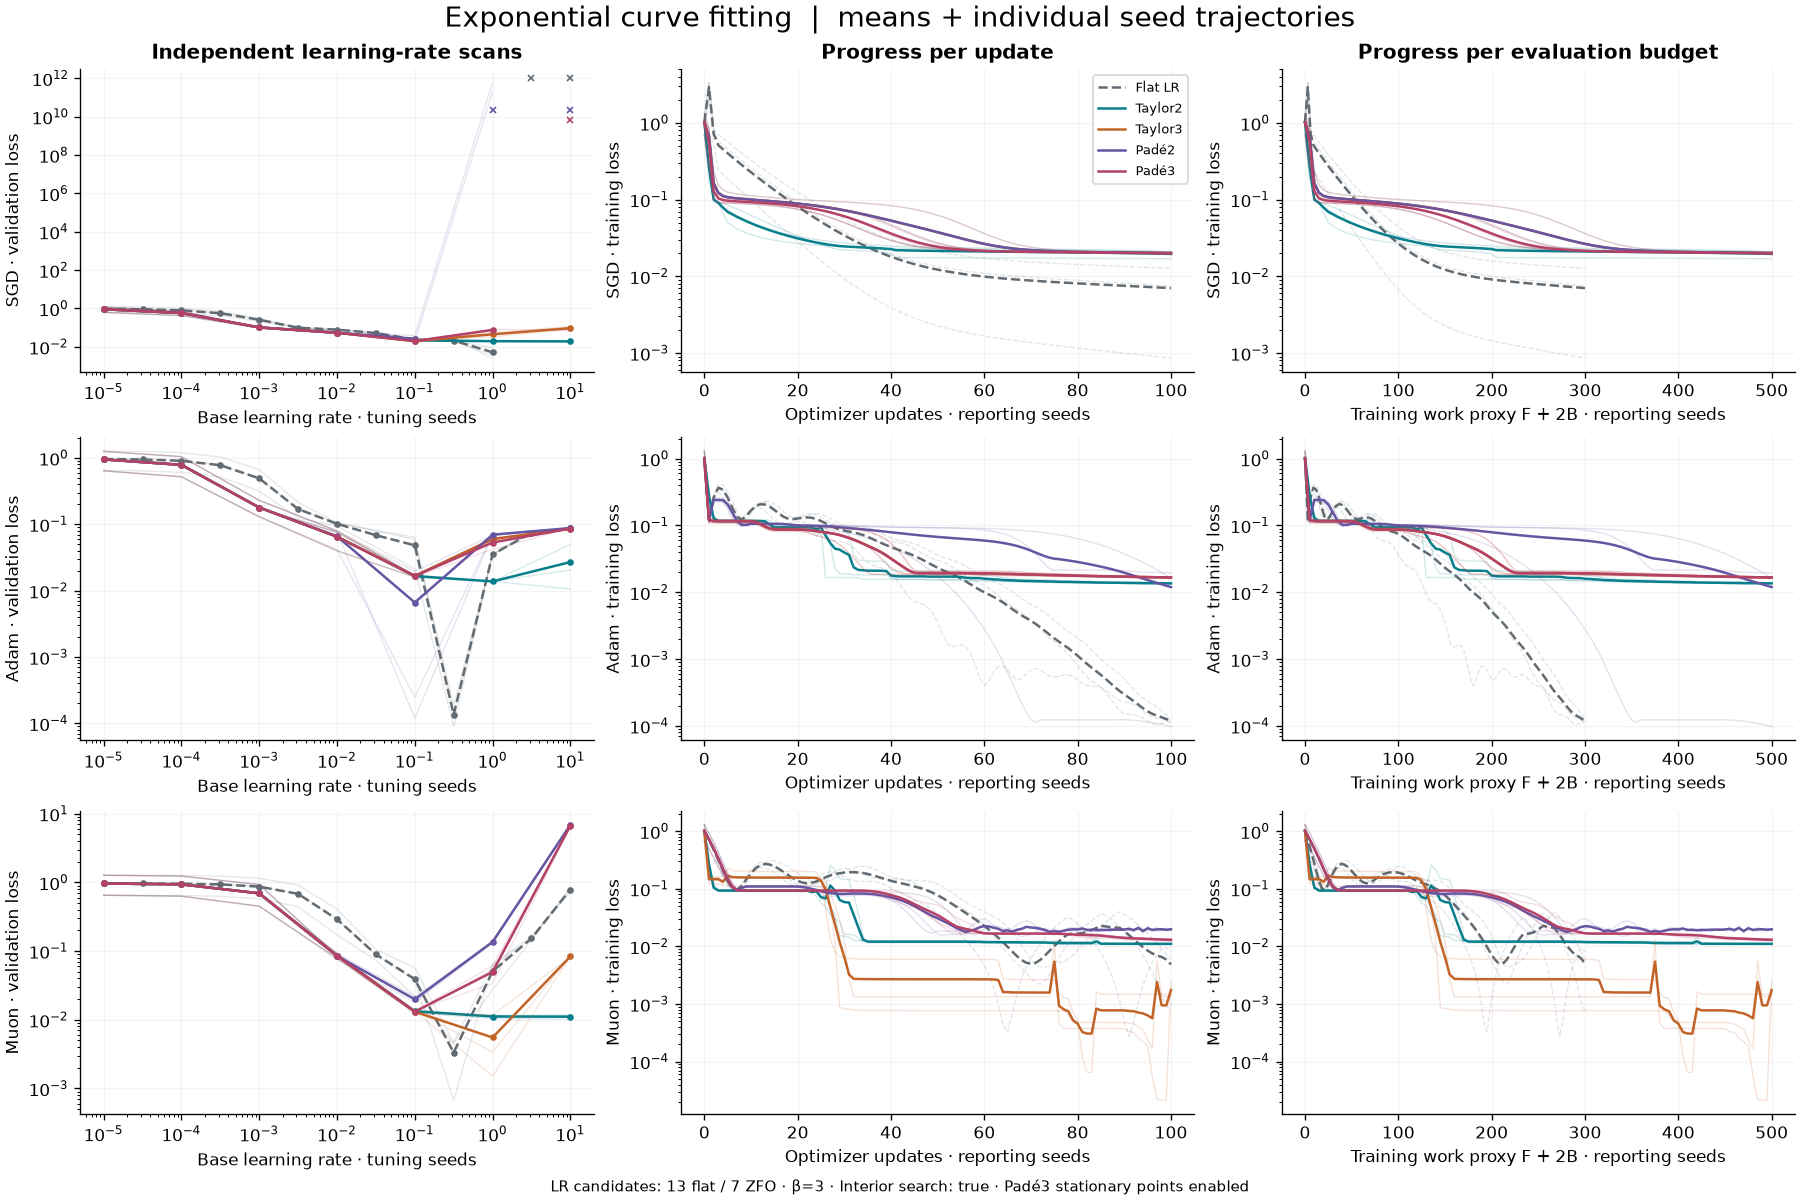

In [7]:
fig = task_figure(data, 'nonlinear_lse')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Logistic regression

**Supervised experiment.** Anisotropic features and stochastic binary labels. Tune on validation cross-entropy; report untouched test cross-entropy and accuracy.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [8]:
outcomes, diagnostics = task_tables(data, 'logistic')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge,Test accuracy ± SD
0,SGD,Flat LR,0.316228,0.4898 ± 0.1,0.4898 ± 0.1,0,0,False,0.7413 ± 0.067
1,SGD,Taylor2,0.100000,0.4892 ± 0.1,0.4842 ± 0.1,0,0,False,0.7413 ± 0.067
2,SGD,Taylor3,0.100000,0.4892 ± 0.1,0.4842 ± 0.1,0,0,False,0.7413 ± 0.067
3,SGD,Padé2,0.100000,0.4892 ± 0.1,0.4842 ± 0.1,0,0,False,0.7413 ± 0.067
4,SGD,Padé3,0.100000,0.4892 ± 0.1,0.4842 ± 0.1,0,0,False,0.7413 ± 0.067
5,Adam,Flat LR,1.000000,0.5102 ± 0.11,0.5102 ± 0.11,0,0,False,0.7396 ± 0.077
6,Adam,Taylor2,0.010000,0.5091 ± 0.11,0.5079 ± 0.11,0,0,False,0.7378 ± 0.075
7,Adam,Taylor3,0.010000,0.5091 ± 0.11,0.5079 ± 0.11,0,0,False,0.7378 ± 0.075
8,Adam,Padé2,1.000000,0.5156 ± 0.13,0.5203 ± 0.14,0,0,False,0.75 ± 0.081
9,Adam,Padé3,0.010000,0.5091 ± 0.11,0.5079 ± 0.11,0,0,False,0.7378 ± 0.075


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.007896 ± 0.00014,100.0,100.0,0.0000,0.0000,0.0,True
1,SGD,Taylor2,-0.0005795 ± 0.00031,0.02102 ± 0.00046,300.0,100.0,0.0000,0.0000,1.0,True
2,SGD,Taylor3,-0.0005795 ± 0.00031,0.02099 ± 0.00016,300.0,100.0,0.0000,0.0000,1.0,True
3,SGD,Padé2,-0.0005769 ± 0.00031,0.02387 ± 0.00037,300.0,100.0,0.0000,0.0000,0.0,True
4,SGD,Padé3,-0.0005777 ± 0.00031,0.02771 ± 0.0037,300.0,100.0,0.0000,0.6667,0.0,True
5,Adam,Flat LR,0 ± 0,0.01334 ± 0.0015,100.0,100.0,0.0000,0.0000,0.0,True
6,Adam,Taylor2,-0.001065 ± 0.0033,0.02798 ± 0.0002,300.0,100.0,0.0000,0.0000,7.0,True
7,Adam,Taylor3,-0.001065 ± 0.0033,0.02991 ± 0.0014,300.0,100.0,0.0000,0.0000,7.0,True
8,Adam,Padé2,0.00544 ± 0.019,0.02995 ± 0.0014,300.0,100.0,0.3333,0.0000,0.0,True
9,Adam,Padé3,-0.001065 ± 0.0033,0.03799 ± 0.013,300.0,100.0,0.0000,0.0000,7.0,True


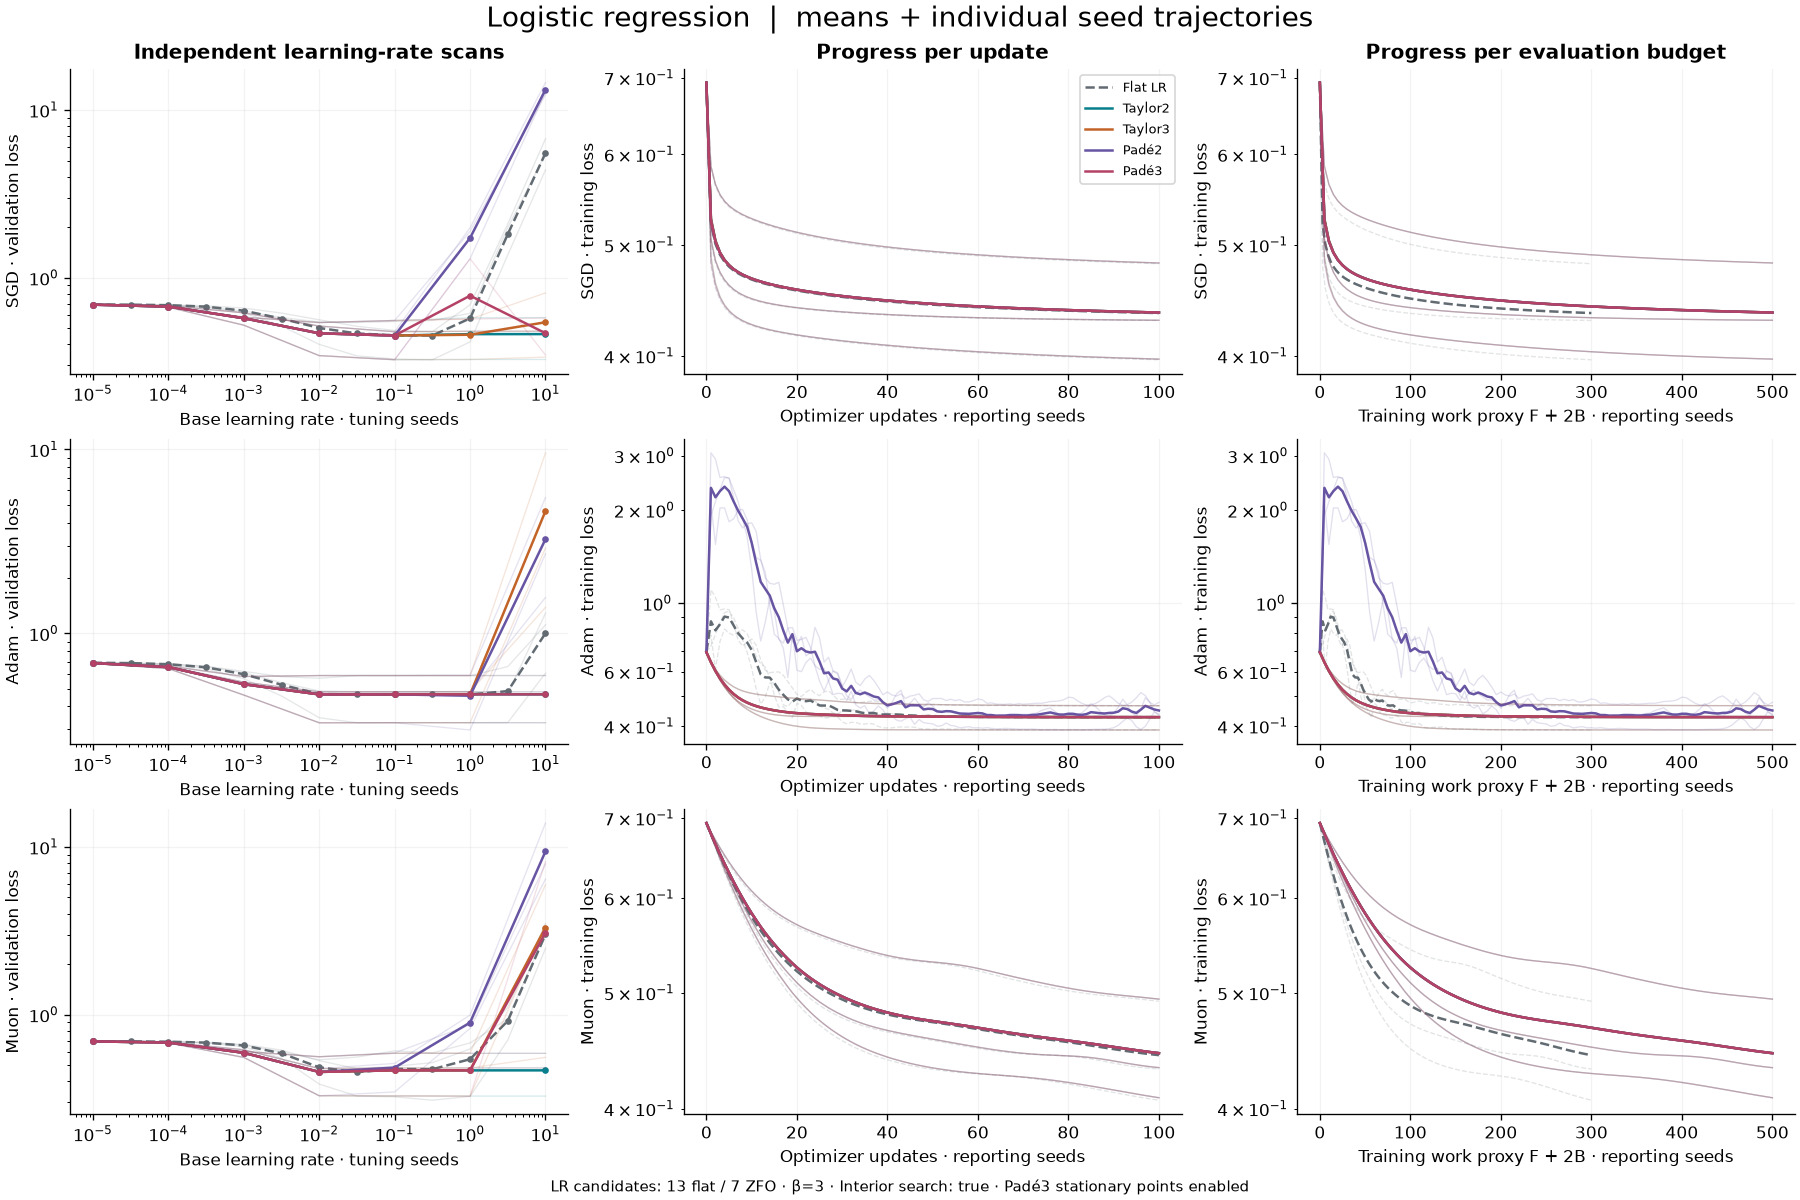

In [9]:
fig = task_figure(data, 'logistic')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Low-rank matrix factorization

**Classical experiment.** Recover a rank-three matrix with two trainable factors. A nonconvex problem with genuine matrix geometry for Muon.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [10]:
outcomes, diagnostics = task_tables(data, 'matrix_factorization')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,10.00,2.982e-09 ± 5.2e-09,2.982e-09 ± 5.2e-09,0,0,True
1,SGD,Taylor2,10.00,5.688e-13 ± 4.1e-13,5.688e-13 ± 4.1e-13,0,0,True
2,SGD,Taylor3,10.00,5.646e-13 ± 4.6e-13,5.646e-13 ± 4.6e-13,0,0,True
3,SGD,Padé2,10.00,failed / incomplete,failed / incomplete,1,1,True
4,SGD,Padé3,10.00,1.869 ± 3.2,0.6177 ± 1.1,0,0,True
5,Adam,Flat LR,0.10,4.018e-06 ± 2.6e-06,4.018e-06 ± 2.6e-06,0,0,False
6,Adam,Taylor2,0.10,1.044e-06 ± 5.8e-07,7.223e-05 ± 4.1e-05,0,0,False
7,Adam,Taylor3,0.10,1.059e-06 ± 6e-07,7.158e-05 ± 4e-05,0,0,False
8,Adam,Padé2,0.01,1.332e-05 ± 9.1e-06,0.0009183 ± 0.00057,0,0,False
9,Adam,Padé3,0.10,1.063e-06 ± 6e-07,7.511e-05 ± 4.2e-05,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.008551 ± 6.5e-05,100.0,100.0000,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,-2.982e-09 ± 5.2e-09,0.02473 ± 0.0012,300.0,100.0000,60.3333,16.0000,14.3333,True
2,SGD,Taylor3,-2.982e-09 ± 5.2e-09,0.02488 ± 0.00046,300.0,100.0000,59.0000,16.0000,18.6667,True
3,SGD,Padé2,failed / incomplete,0.0251 ± 0.0081,259.0,86.3333,16.0000,16.0000,0.0000,True
4,SGD,Padé3,1.869 ± 3.2,0.02673 ± 0.00057,300.0,100.0000,16.0000,27.6667,20.6667,True
5,Adam,Flat LR,0 ± 0,0.01146 ± 6.2e-05,100.0,100.0000,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-2.974e-06 ± 2e-06,0.03926 ± 0.00081,300.0,100.0000,0.0000,0.0000,96.3333,True
7,Adam,Taylor3,-2.959e-06 ± 2e-06,0.0387 ± 0.0021,300.0,100.0000,0.0000,0.0000,97.0000,True
8,Adam,Padé2,9.303e-06 ± 6.5e-06,0.03713 ± 0.0011,300.0,100.0000,0.0000,0.0000,0.0000,True
9,Adam,Padé3,-2.955e-06 ± 2e-06,0.04335 ± 0.0013,300.0,100.0000,0.0000,94.3333,1.0000,True


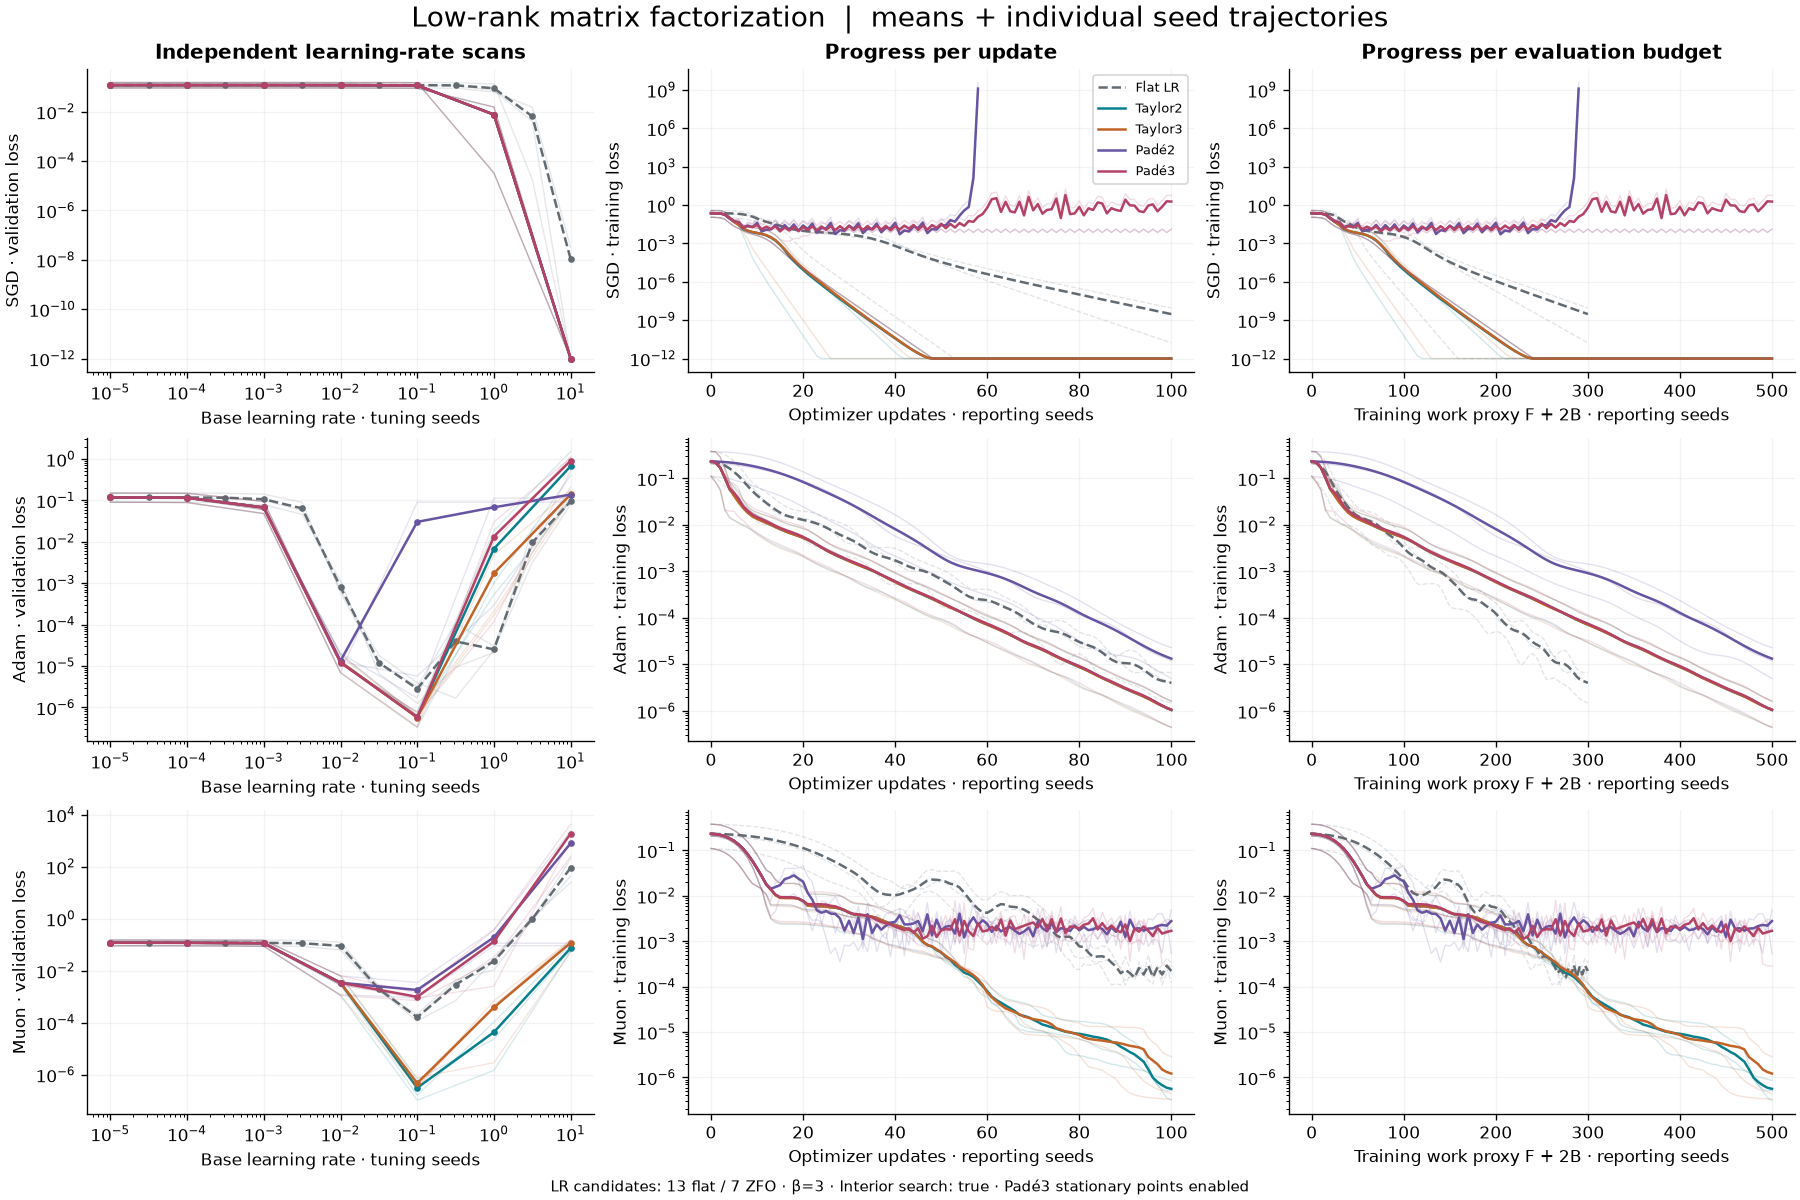

In [11]:
fig = task_figure(data, 'matrix_factorization')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Rosenbrock valley

**Classical experiment.** A curved narrow valley with seed-perturbed starts. Local step selection cannot repair a poorly aligned direction.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [12]:
outcomes, diagnostics = task_tables(data, 'rosenbrock')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,0.003162,failed / incomplete,failed / incomplete,1,1,False
1,SGD,Taylor2,1.000000,1.402 ± 1.6,2.254 ± 1.8,0,0,False
2,SGD,Taylor3,0.001000,3.349 ± 0.3,3.702 ± 0.24,0,0,False
3,SGD,Padé2,0.001000,0.6816 ± 0.97,0.8517 ± 1.3,0,0,False
4,SGD,Padé3,0.001000,1.671 ± 0.14,2.242 ± 0.12,0,0,False
5,Adam,Flat LR,0.316228,0.7948 ± 0.14,0.7948 ± 0.14,0,0,False
6,Adam,Taylor2,1.000000,0.0008446 ± 0.00073,0.03022 ± 0.024,0,0,False
7,Adam,Taylor3,0.100000,0.2332 ± 0.24,1.747 ± 0.84,0,0,False
8,Adam,Padé2,0.100000,0.9397 ± 0.18,2.464 ± 0.18,0,0,False
9,Adam,Padé3,1.000000,0.1885 ± 0.24,0.2859 ± 0.28,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,failed / incomplete,0.007755 ± 0.0058,70.0,70.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,failed / incomplete,0.02432 ± 0.00025,300.0,100.0,0.0000,0.0000,100.0000,True
2,SGD,Taylor3,failed / incomplete,0.02481 ± 0.00088,300.0,100.0,0.0000,0.0000,67.3333,True
3,SGD,Padé2,failed / incomplete,0.02851 ± 0.0045,300.0,100.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,failed / incomplete,0.02528 ± 0.00063,300.0,100.0,0.0000,0.6667,1.6667,True
5,Adam,Flat LR,0 ± 0,0.01205 ± 7.1e-05,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-0.7939 ± 0.13,0.03304 ± 0.00089,300.0,100.0,0.0000,0.0000,91.6667,True
7,Adam,Taylor3,-0.5615 ± 0.36,0.03093 ± 0.0002,300.0,100.0,10.6667,0.0000,11.3333,True
8,Adam,Padé2,0.145 ± 0.058,0.0334 ± 0.00044,300.0,100.0,6.0000,0.0000,0.0000,True
9,Adam,Padé3,-0.6063 ± 0.15,0.03143 ± 0.00029,300.0,100.0,22.0000,19.0000,43.0000,True


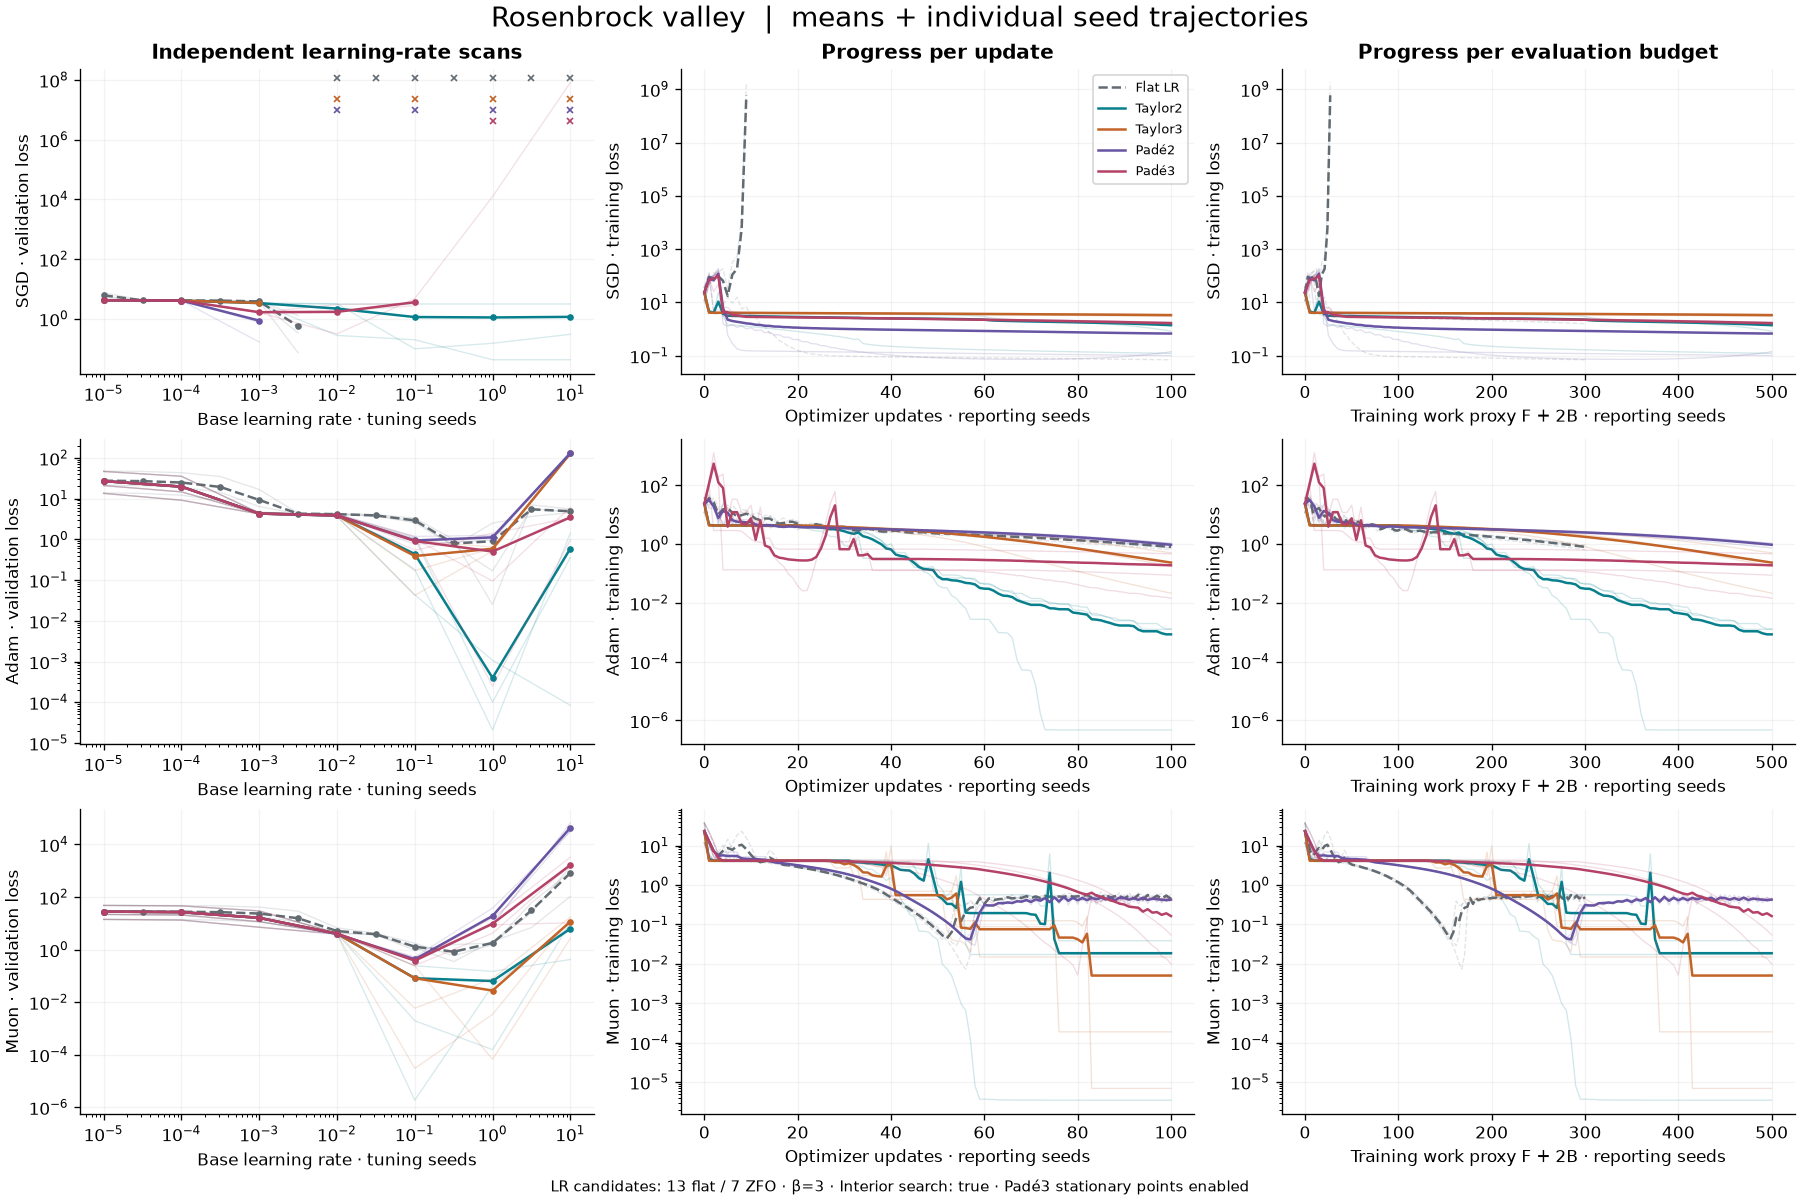

In [13]:
fig = task_figure(data, 'rosenbrock')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Beale surface

**Classical experiment.** A two-variable nonlinear least-squares landscape. Includes seed-perturbed difficult starts and unstable learning rates.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [14]:
outcomes, diagnostics = task_tables(data, 'beale')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,0.031623,failed / incomplete,failed / incomplete,1,1,False
1,SGD,Taylor2,0.010000,1.179 ± 0.011,1.28 ± 0.018,0,0,False
2,SGD,Taylor3,0.010000,0.4258 ± 0.72,0.4675 ± 0.75,0,0,False
3,SGD,Padé2,0.010000,failed / incomplete,failed / incomplete,1,1,False
4,SGD,Padé3,0.001000,1.355 ± 0.0097,1.388 ± 0.011,0,0,False
5,Adam,Flat LR,1.000000,0.008503 ± 0.0025,0.008503 ± 0.0025,0,0,False
6,Adam,Taylor2,0.100000,0.8062 ± 0.052,0.8988 ± 0.095,0,0,False
7,Adam,Taylor3,1.000000,0.2819 ± 0.49,0.3076 ± 0.53,0,0,False
8,Adam,Padé2,0.100000,0.9029 ± 0.0015,1.038 ± 0.014,0,0,False
9,Adam,Padé3,0.100000,0.8918 ± 0.022,1.028 ± 0.017,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,failed / incomplete,0.01756 ± 0.015,68.0,68.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,failed / incomplete,0.03748 ± 0.0013,300.0,100.0,0.0000,0.0000,73.3333,True
2,SGD,Taylor3,failed / incomplete,0.03884 ± 0.0024,300.0,100.0,0.0000,0.0000,33.3333,True
3,SGD,Padé2,failed / incomplete,0.02563 ± 0.02,207.0,69.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,failed / incomplete,0.03701 ± 0.00046,300.0,100.0,0.0000,0.3333,0.3333,True
5,Adam,Flat LR,0 ± 0,0.02131 ± 0.00033,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,0.7977 ± 0.05,0.0443 ± 0.00021,300.0,100.0,1.6667,0.0000,28.6667,True
7,Adam,Taylor3,0.2734 ± 0.49,0.04459 ± 0.00069,300.0,100.0,10.3333,0.0000,65.0000,True
8,Adam,Padé2,0.8944 ± 0.0017,0.04746 ± 0.0011,300.0,100.0,7.3333,0.0000,0.0000,True
9,Adam,Padé3,0.8833 ± 0.025,0.04822 ± 0.0024,300.0,100.0,3.6667,1.0000,14.3333,True


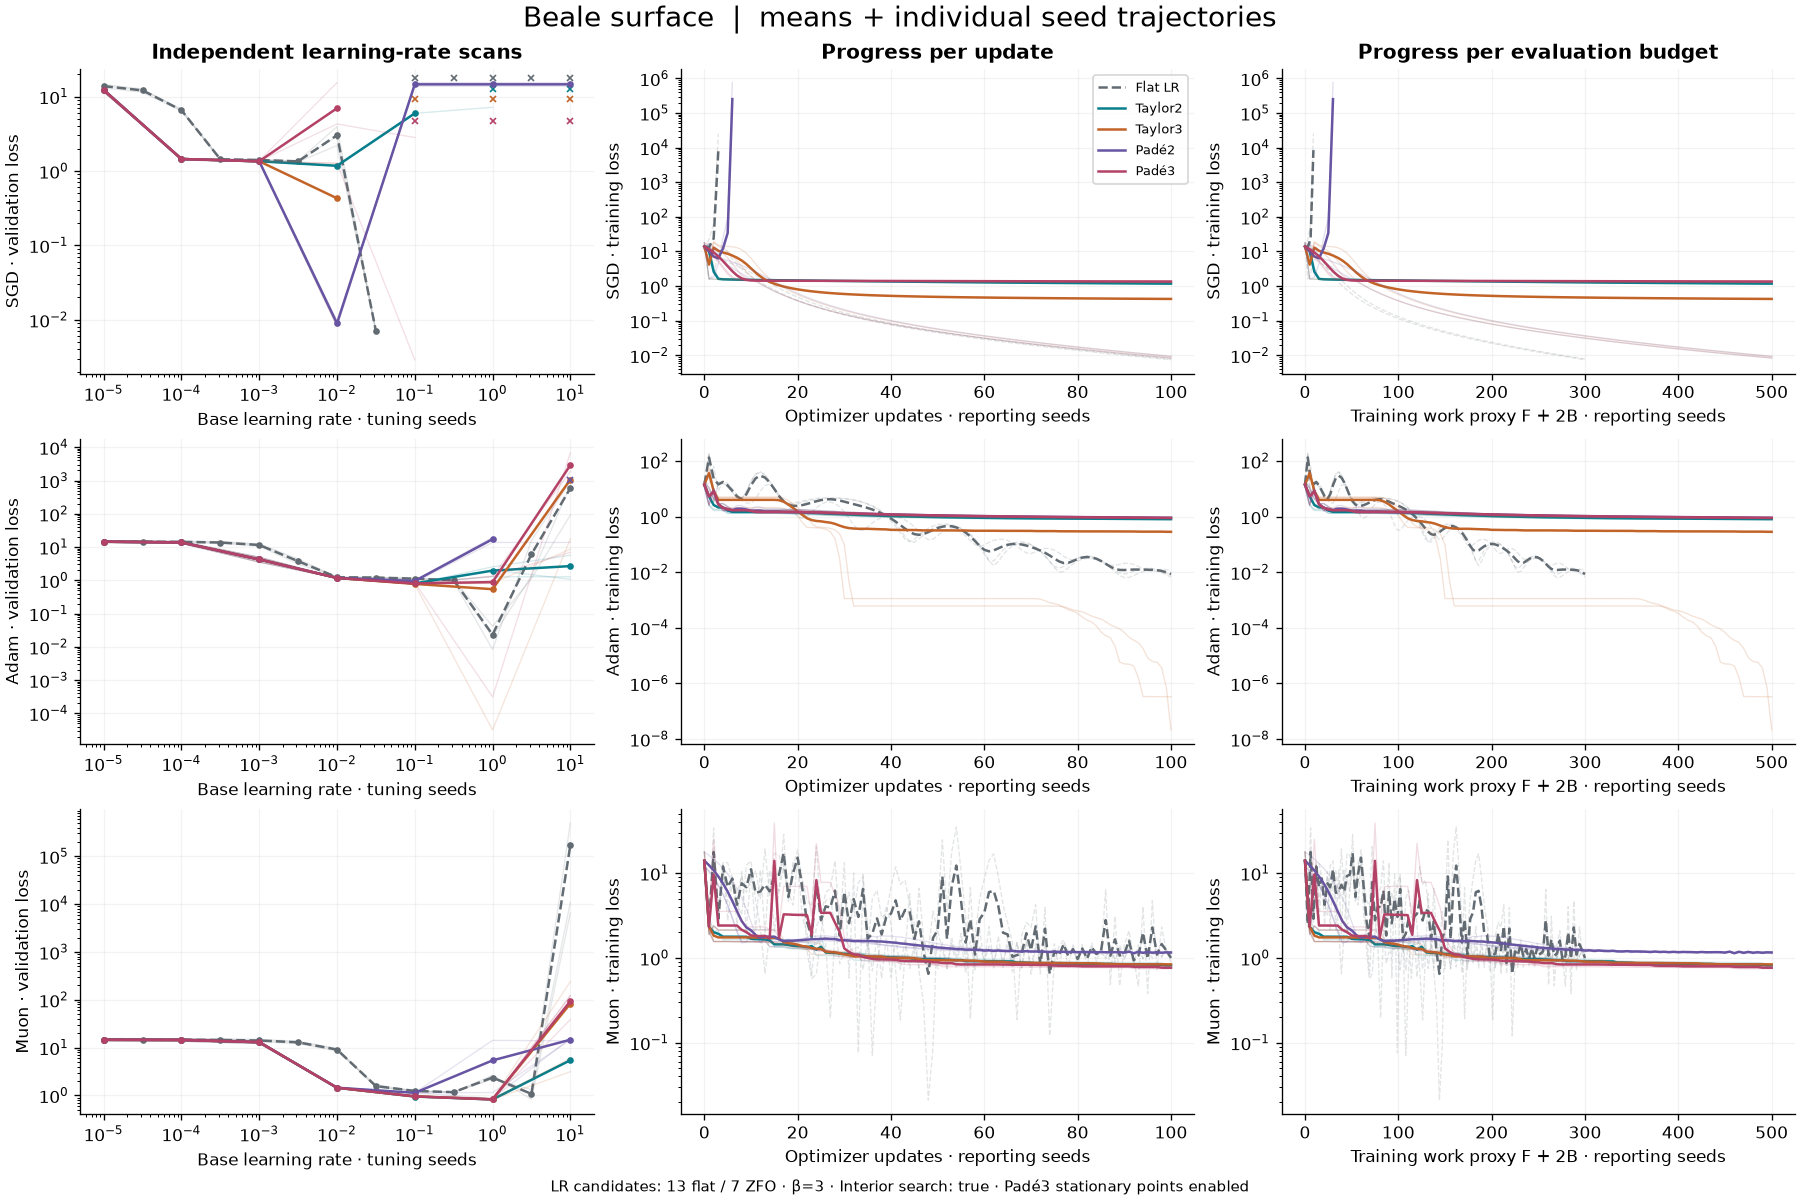

In [15]:
fig = task_figure(data, 'beale')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Rastrigin landscape

**Stress experiment.** Many local minima. Good local descent does not guarantee global progress; a deliberate limitation test.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [16]:
outcomes, diagnostics = task_tables(data, 'rastrigin')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,0.001,30.84 ± 12,30.84 ± 12,0,0,False
1,SGD,Taylor2,0.001,30.84 ± 12,30.84 ± 12,0,0,False
2,SGD,Taylor3,0.001,30.84 ± 12,30.84 ± 12,0,0,False
3,SGD,Padé2,0.001,30.84 ± 12,30.84 ± 12,0,0,False
4,SGD,Padé3,0.001,30.84 ± 12,30.84 ± 12,0,0,False
5,Adam,Flat LR,0.100,30.84 ± 12,30.84 ± 12,0,0,False
6,Adam,Taylor2,0.100,30.84 ± 12,30.86 ± 12,0,0,False
7,Adam,Taylor3,10.000,30.84 ± 12,30.86 ± 12,0,0,True
8,Adam,Padé2,0.100,30.84 ± 12,30.88 ± 12,0,0,False
9,Adam,Padé3,0.100,30.84 ± 12,30.86 ± 12,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.01009 ± 0.00028,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,9.474e-15 ± 4.1e-15,0.02492 ± 0.00044,300.0,100.0,94.0000,94.0000,2.3333,True
2,SGD,Taylor3,4.737e-15 ± 4.1e-15,0.029 ± 0.0033,300.0,100.0,94.3333,94.3333,3.0000,True
3,SGD,Padé2,1.184e-14 ± 4.1e-15,0.02487 ± 0.00016,300.0,100.0,87.6667,87.6667,0.0000,True
4,SGD,Padé3,1.066e-14 ± 3.6e-15,0.0239 ± 0.00031,300.0,100.0,94.0000,95.0000,2.3333,True
5,Adam,Flat LR,0 ± 0,0.01451 ± 0.0015,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-0.0004196 ± 0.00049,0.03192 ± 0.0019,300.0,100.0,0.0000,0.0000,99.3333,True
7,Adam,Taylor3,-0.0004261 ± 0.00048,0.03243 ± 0.00046,300.0,100.0,0.0000,0.0000,100.0000,True
8,Adam,Padé2,0.000447 ± 0.00076,0.0314 ± 0.00087,300.0,100.0,0.6667,0.0000,0.0000,True
9,Adam,Padé3,-0.0003403 ± 0.00056,0.03305 ± 0.0028,300.0,100.0,0.0000,1.0000,96.0000,True


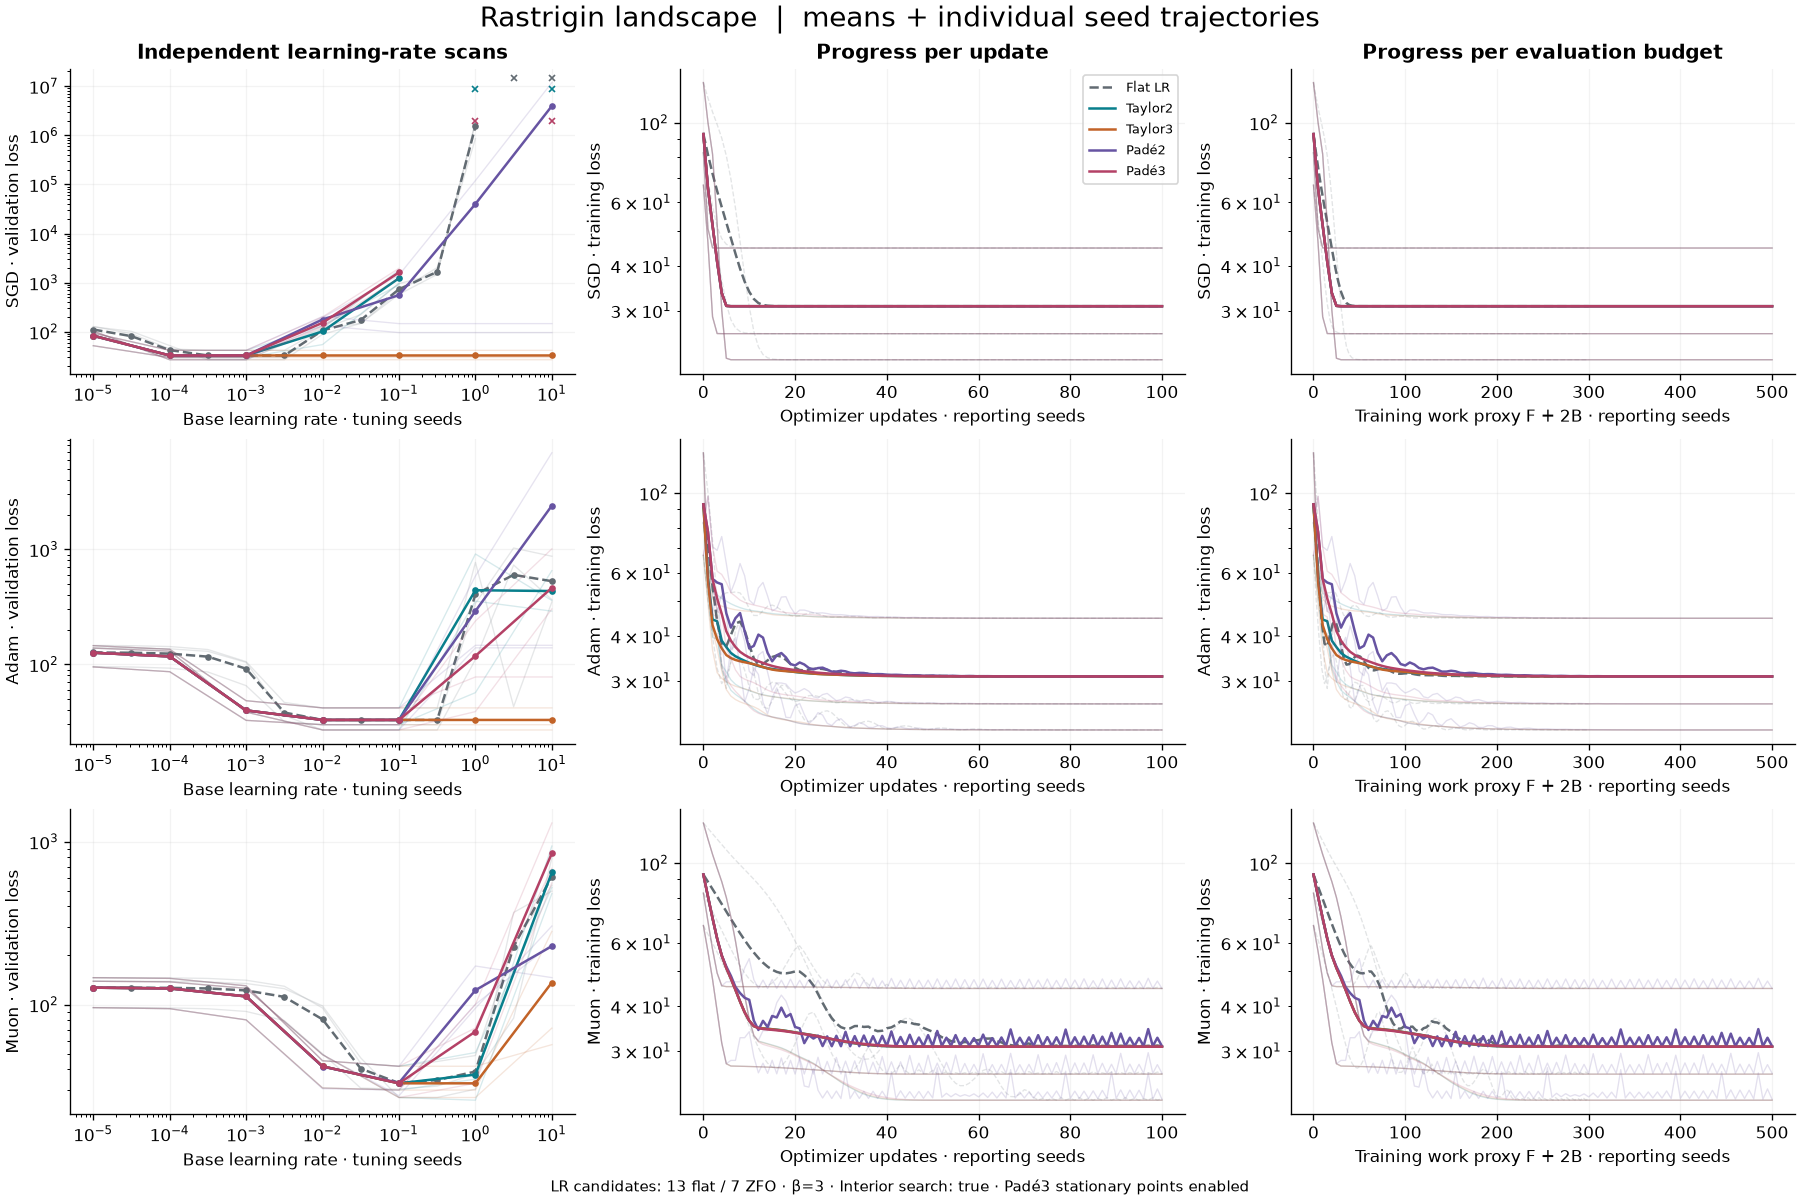

In [17]:
fig = task_figure(data, 'rastrigin')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Minibatch noisy regression

**Supervised experiment.** Noisy targets and batches of sixteen. Fixed-batch probes are coherent but may pick steps that generalize poorly to the next batch.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [18]:
outcomes, diagnostics = task_tables(data, 'noisy_regression')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge
0,SGD,Flat LR,0.031623,0.2567 ± 0.031,0.2567 ± 0.031,0,0,False
1,SGD,Taylor2,0.010000,0.2575 ± 0.032,0.2746 ± 0.022,0,0,False
2,SGD,Taylor3,0.010000,0.2575 ± 0.032,0.2746 ± 0.022,0,0,False
3,SGD,Padé2,0.010000,0.2575 ± 0.032,0.2746 ± 0.022,0,0,False
4,SGD,Padé3,0.010000,0.2575 ± 0.032,0.2747 ± 0.022,0,0,False
5,Adam,Flat LR,0.031623,0.2483 ± 0.028,0.2483 ± 0.028,0,0,False
6,Adam,Taylor2,0.010000,0.2477 ± 0.031,0.2494 ± 0.022,0,0,False
7,Adam,Taylor3,0.010000,0.2477 ± 0.031,0.2494 ± 0.022,0,0,False
8,Adam,Padé2,0.010000,0.2474 ± 0.031,0.25 ± 0.022,0,0,False
9,Adam,Padé3,0.010000,0.2477 ± 0.031,0.2494 ± 0.022,0,0,False


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.008559 ± 0.00037,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,0.0007131 ± 0.001,0.02243 ± 0.00012,300.0,100.0,0.0000,0.0000,0.0000,True
2,SGD,Taylor3,0.0007131 ± 0.001,0.0232 ± 0.00084,300.0,100.0,0.0000,0.0000,0.0000,True
3,SGD,Padé2,0.0007131 ± 0.001,0.02978 ± 0.0043,300.0,100.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,0.0008042 ± 0.0011,0.02531 ± 0.0005,300.0,100.0,0.0000,13.0000,2.6667,True
5,Adam,Flat LR,0 ± 0,0.01269 ± 0.00024,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-0.0006135 ± 0.0033,0.03148 ± 0.00042,300.0,100.0,11.3333,0.0000,3.6667,True
7,Adam,Taylor3,-0.0006135 ± 0.0033,0.0508 ± 0.012,300.0,100.0,11.3333,0.0000,3.6667,True
8,Adam,Padé2,-0.0009085 ± 0.003,0.04237 ± 0.012,300.0,100.0,10.0000,0.0000,0.0000,True
9,Adam,Padé3,-0.0006151 ± 0.0033,0.03014 ± 0.00073,300.0,100.0,11.3333,2.6667,4.3333,True


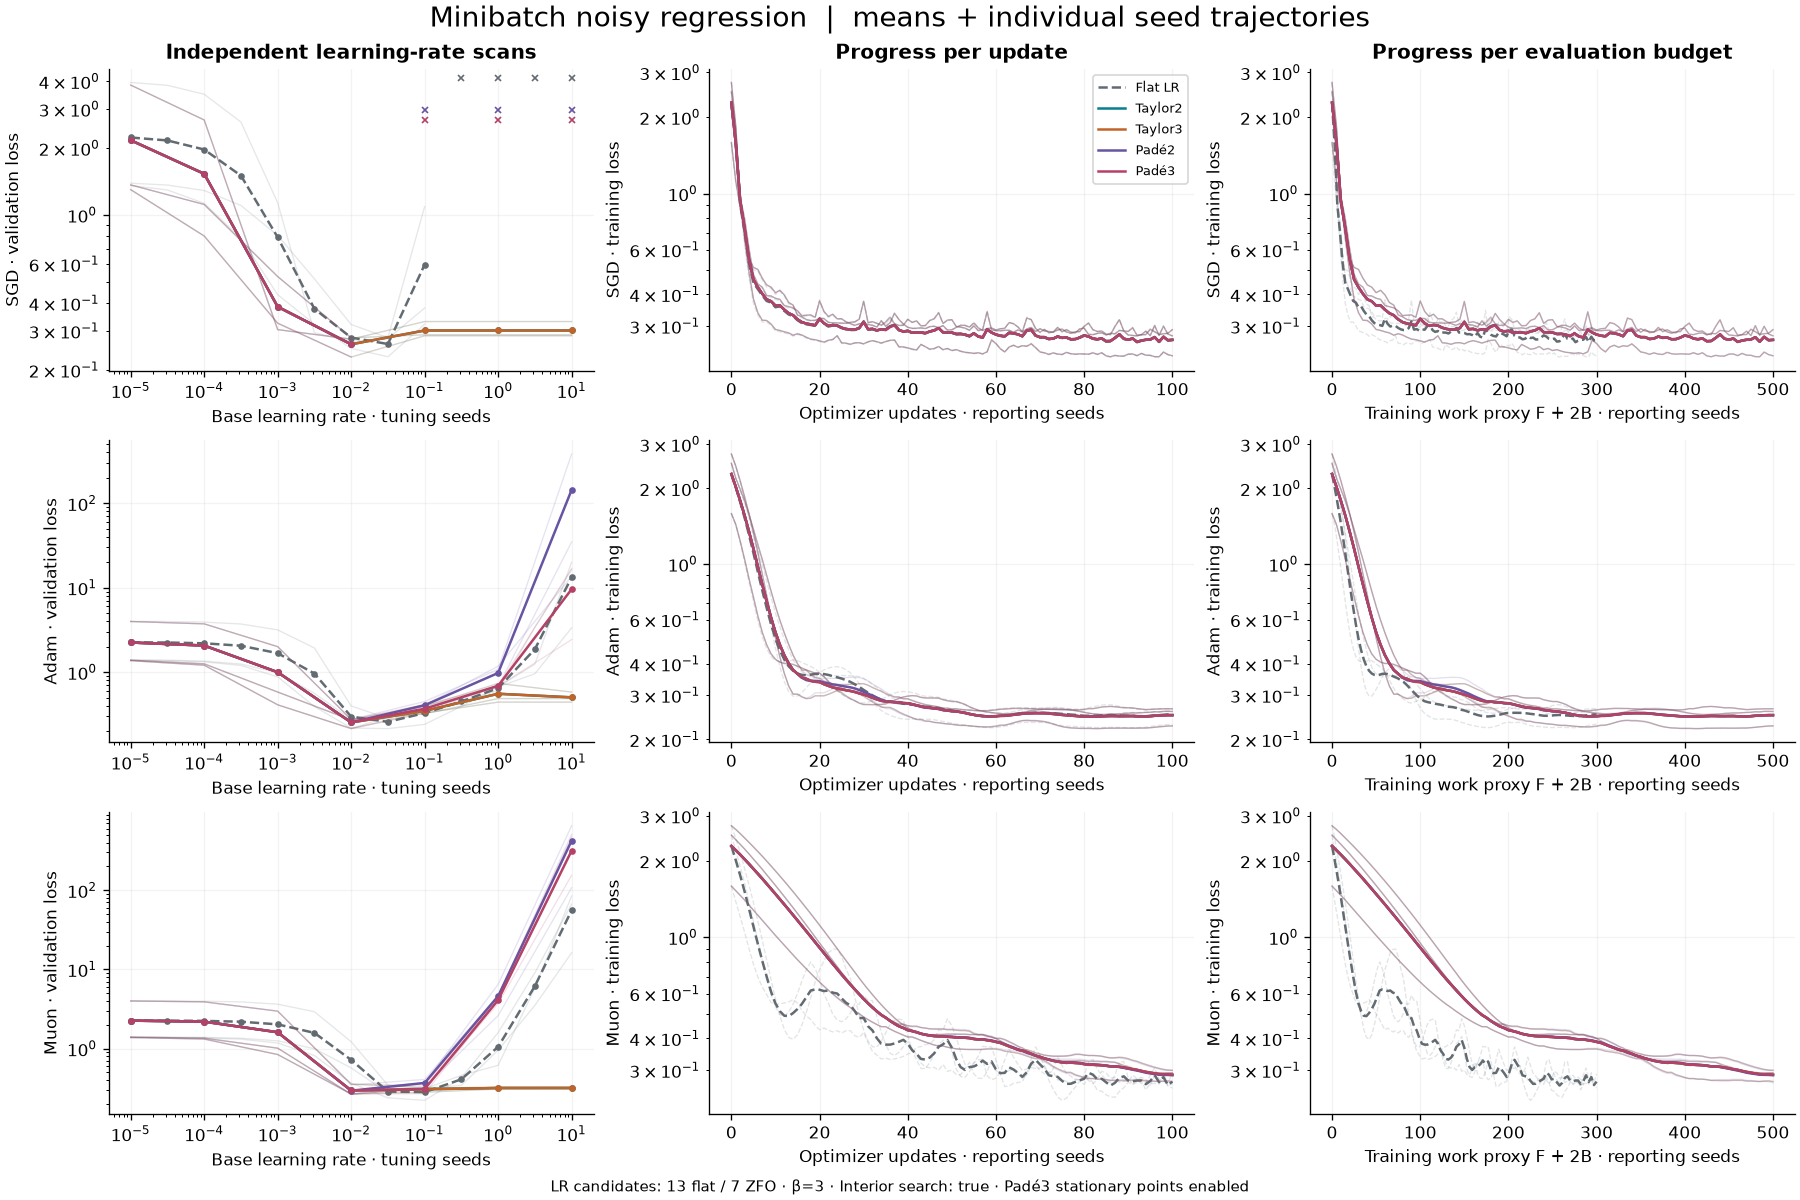

In [19]:
fig = task_figure(data, 'noisy_regression')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Two moons · tanh MLP

**Supervised experiment.** Nonlinear classification with a smooth 16-unit network, finite samples, and held-out validation/test data.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [20]:
outcomes, diagnostics = task_tables(data, 'moons')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge,Test accuracy ± SD
0,SGD,Flat LR,3.162278,0.05995 ± 0.0086,0.05995 ± 0.0086,0,0,False,0.9861 ± 0.003
1,SGD,Taylor2,10.000000,0.02993 ± 0.0046,0.06336 ± 0.0089,0,0,True,0.9931 ± 0.008
2,SGD,Taylor3,1.000000,0.08567 ± 0.0038,0.1651 ± 0.02,0,0,False,0.9757 ± 0.008
3,SGD,Padé2,1.000000,0.06268 ± 0.0071,0.1368 ± 0.023,0,0,False,0.9861 ± 0.003
4,SGD,Padé3,1.000000,0.07685 ± 0.0044,0.1517 ± 0.02,0,0,False,0.9809 ± 0.003
5,Adam,Flat LR,0.316228,0.01531 ± 0.0066,0.01531 ± 0.0066,0,0,False,0.9913 ± 0.003
6,Adam,Taylor2,0.100000,0.02112 ± 0.0073,0.02076 ± 0.0075,0,0,False,0.9931 ± 0.003
7,Adam,Taylor3,0.100000,0.02119 ± 0.007,0.02099 ± 0.007,0,0,False,0.9931 ± 0.003
8,Adam,Padé2,0.100000,0.01548 ± 0.0063,0.0159 ± 0.0075,0,0,False,0.9913 ± 0.003
9,Adam,Padé3,0.100000,0.01759 ± 0.007,0.01685 ± 0.0059,0,0,False,0.9948 ± 0


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.01635 ± 0.0002,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,-0.03003 ± 0.012,0.04419 ± 0.0011,300.0,100.0,0.0000,0.0000,93.0000,True
2,SGD,Taylor3,0.02572 ± 0.0053,0.04169 ± 0.00031,300.0,100.0,0.0000,0.0000,97.0000,True
3,SGD,Padé2,0.00273 ± 0.0016,0.04483 ± 0.0036,300.0,100.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,0.0169 ± 0.0052,0.04398 ± 0.00085,300.0,100.0,0.0000,0.6667,62.6667,True
5,Adam,Flat LR,0 ± 0,0.02076 ± 0.001,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,0.005805 ± 0.0078,0.06882 ± 0.0057,300.0,100.0,0.0000,0.0000,8.3333,True
7,Adam,Taylor3,0.005877 ± 0.0075,0.06215 ± 0.0045,300.0,100.0,0.0000,0.0000,8.6667,True
8,Adam,Padé2,0.0001655 ± 0.0005,0.06596 ± 0.0044,300.0,100.0,0.0000,0.0000,0.0000,True
9,Adam,Padé3,0.002278 ± 0.0055,0.05877 ± 0.0025,300.0,100.0,0.6667,9.6667,6.3333,True


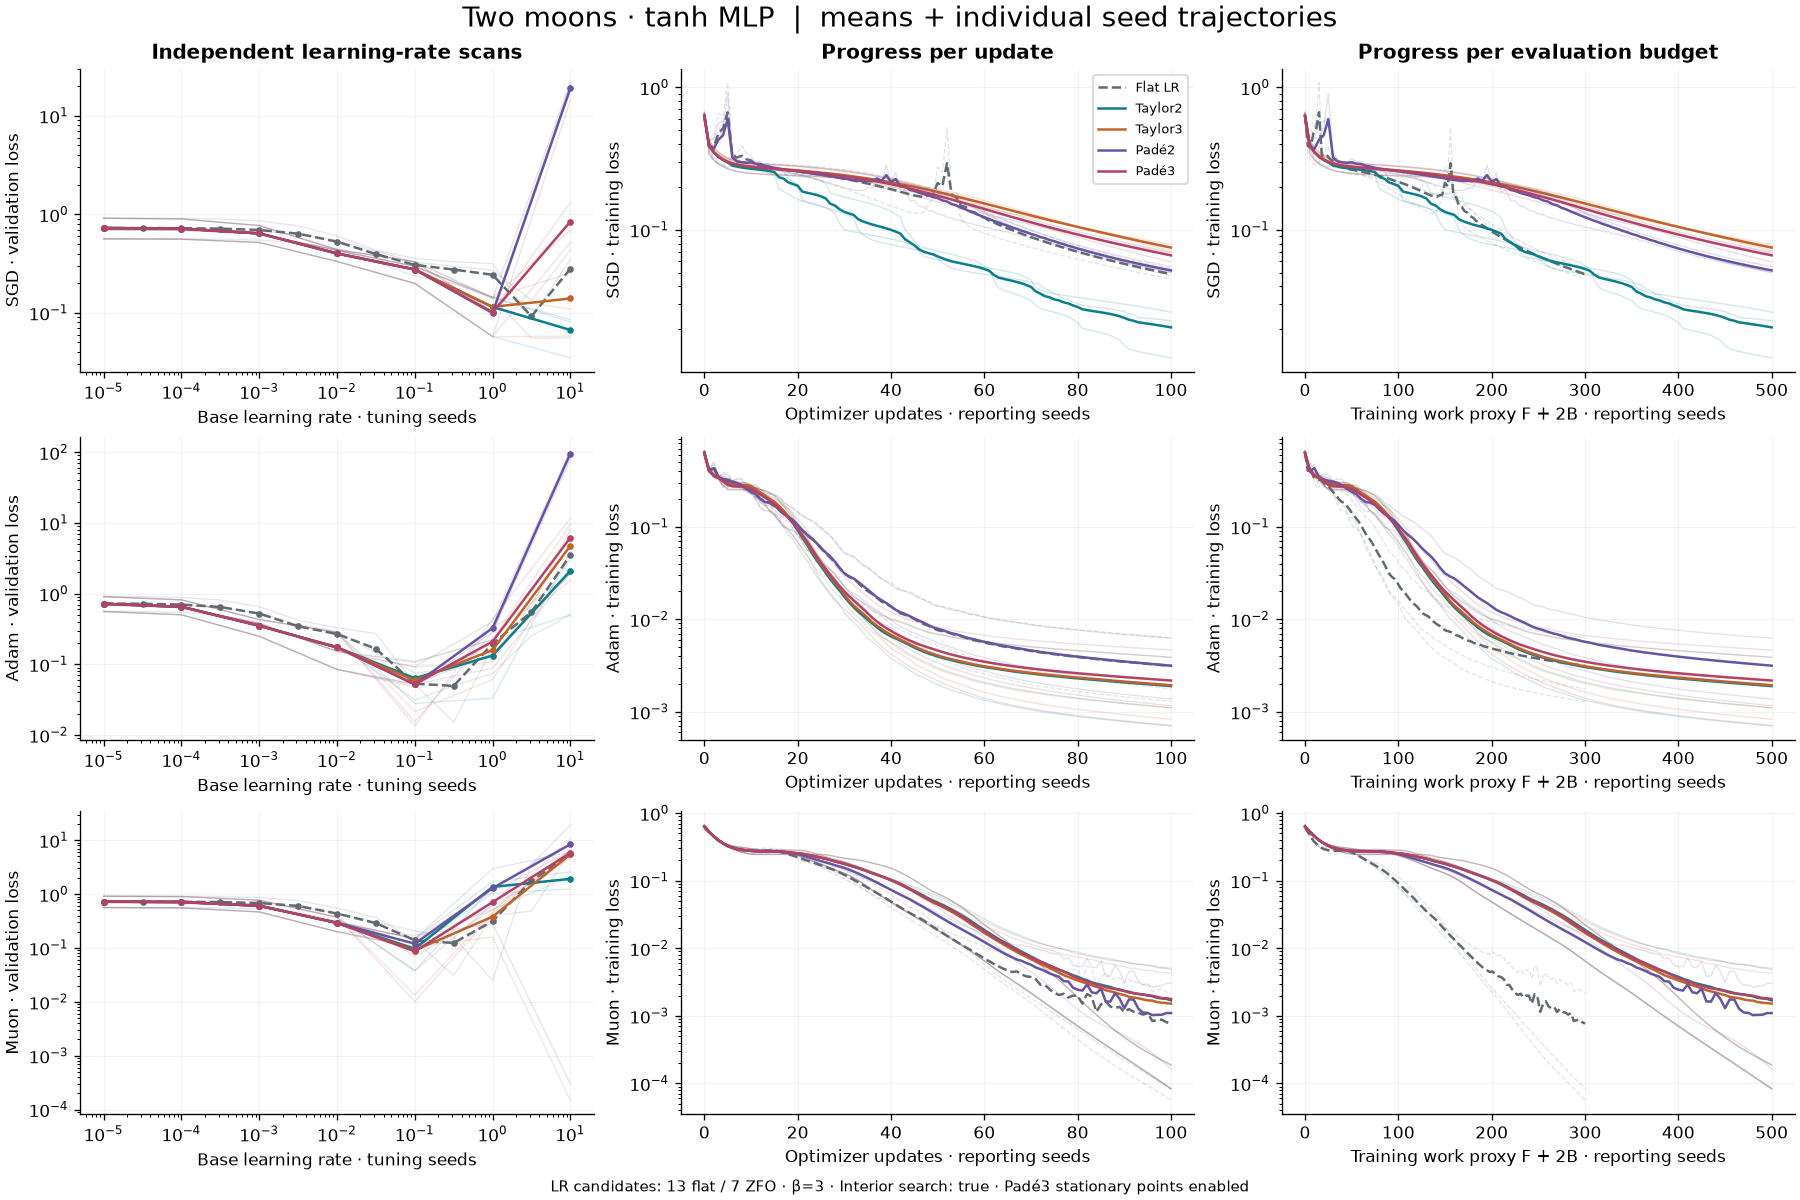

In [21]:
fig = task_figure(data, 'moons')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## XOR · ReLU MLP

**Stress experiment.** A small piecewise-linear network crosses activation boundaries. The loss need not match a smooth Taylor model along the whole search interval.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [22]:
outcomes, diagnostics = task_tables(data, 'xor')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge,Test accuracy ± SD
0,SGD,Flat LR,3.162278,0.1453 ± 0.11,0.1453 ± 0.11,0,0,False,0.9497 ± 0.048
1,SGD,Taylor2,10.000000,0.06643 ± 0.0093,0.08497 ± 0.01,0,0,True,0.9774 ± 0.012
2,SGD,Taylor3,1.000000,0.08473 ± 0.017,0.1096 ± 0.02,0,0,False,0.9792 ± 0.018
3,SGD,Padé2,1.000000,0.1056 ± 0.025,0.1531 ± 0.059,0,0,False,0.9653 ± 0.02
4,SGD,Padé3,1.000000,0.08328 ± 0.016,0.1076 ± 0.019,0,0,False,0.9757 ± 0.011
5,Adam,Flat LR,0.100000,0.04627 ± 0.019,0.04627 ± 0.019,0,0,False,0.9809 ± 0.016
6,Adam,Taylor2,0.010000,0.08335 ± 0.018,0.12 ± 0.016,0,0,False,0.9774 ± 0.012
7,Adam,Taylor3,0.010000,0.0871 ± 0.02,0.1295 ± 0.021,0,0,False,0.9774 ± 0.012
8,Adam,Padé2,0.010000,0.08335 ± 0.018,0.12 ± 0.016,0,0,False,0.9774 ± 0.012
9,Adam,Padé3,0.010000,0.08335 ± 0.018,0.12 ± 0.016,0,0,False,0.9774 ± 0.012


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.01616 ± 0.002,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,-0.07884 ± 0.11,0.03725 ± 0.00022,300.0,100.0,0.0000,0.0000,97.3333,True
2,SGD,Taylor3,-0.06054 ± 0.11,0.04187 ± 0.0016,300.0,100.0,0.0000,0.0000,75.6667,True
3,SGD,Padé2,-0.03964 ± 0.094,0.06118 ± 0.019,300.0,100.0,13.0000,0.0000,0.0000,True
4,SGD,Padé3,-0.06199 ± 0.11,0.05731 ± 0.0068,300.0,100.0,0.0000,10.3333,69.6667,True
5,Adam,Flat LR,0 ± 0,0.0167 ± 0.00061,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,0.03707 ± 0.0047,0.06547 ± 0.022,300.0,100.0,0.0000,0.0000,0.0000,True
7,Adam,Taylor3,0.04082 ± 0.0054,0.06314 ± 0.012,300.0,100.0,0.0000,0.0000,5.6667,True
8,Adam,Padé2,0.03707 ± 0.0047,0.05115 ± 0.0031,300.0,100.0,0.0000,0.0000,0.0000,True
9,Adam,Padé3,0.03707 ± 0.0047,0.05917 ± 0.011,300.0,100.0,0.0000,6.6667,0.0000,True


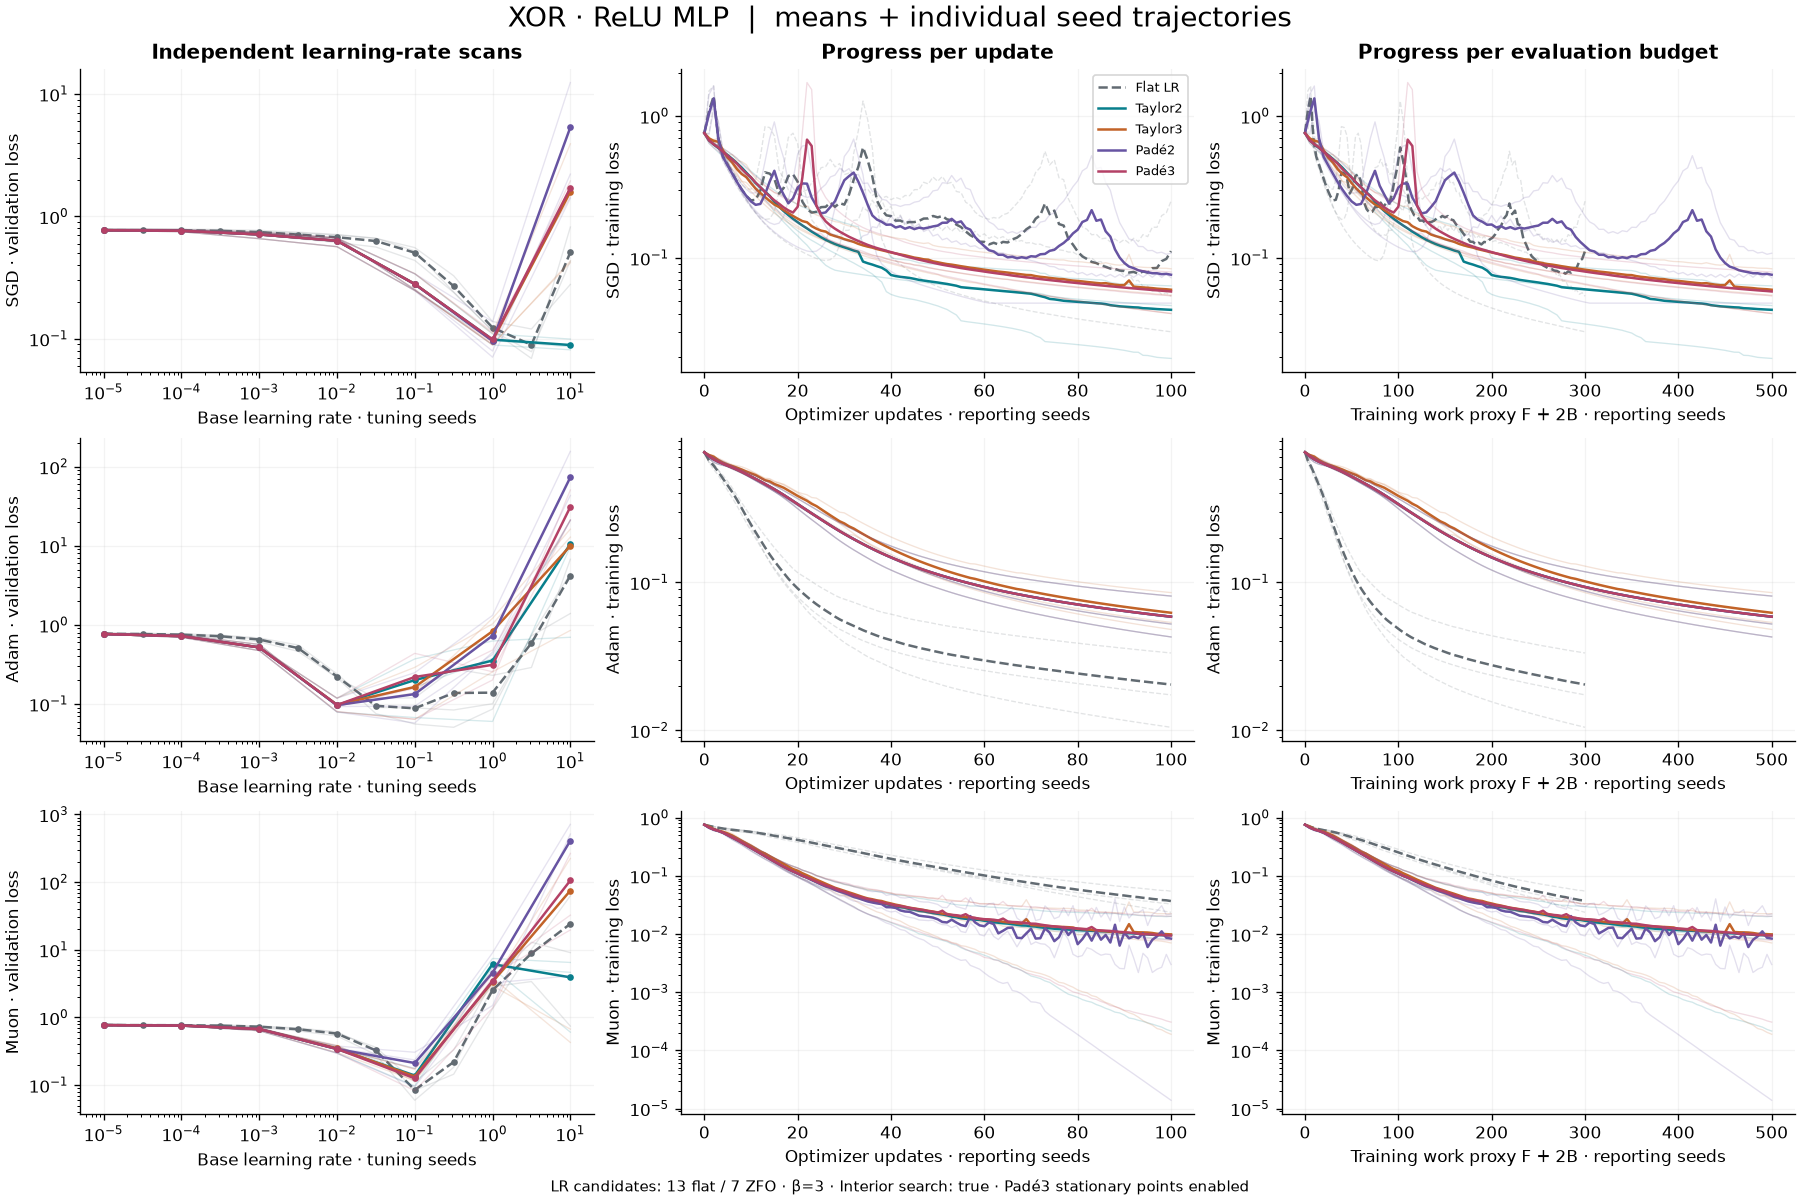

In [23]:
fig = task_figure(data, 'xor')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Moons · 30% label noise

**Stress experiment.** A tanh classifier trained on corrupted labels in minibatches. Validation and test labels remain clean to expose overfitting.

All 15 pairings below use the same seed-defined task instances. Lower loss is better; Δ loss is ZFO minus the paired flat baseline. The equal-work and final columns may favor different choices.

In [24]:
outcomes, diagnostics = task_tables(data, 'noisy_labels')
display(outcomes)
display(diagnostics.round(4))

,Base,Selector,LR,Final loss ± SD,Equal-work loss ± SD,Equal-work failed seeds,Failed seeds,Grid edge,Test accuracy ± SD
0,SGD,Flat LR,0.316228,0.4593 ± 0.023,0.4593 ± 0.023,0,0,False,0.8299 ± 0.029
1,SGD,Taylor2,0.100000,0.4603 ± 0.023,0.4881 ± 0.026,0,0,False,0.8281 ± 0.028
2,SGD,Taylor3,0.100000,0.4603 ± 0.023,0.4881 ± 0.026,0,0,False,0.8281 ± 0.028
3,SGD,Padé2,0.100000,0.4603 ± 0.023,0.4881 ± 0.026,0,0,False,0.8281 ± 0.028
4,SGD,Padé3,0.100000,0.4603 ± 0.023,0.4881 ± 0.026,0,0,False,0.8281 ± 0.028
5,Adam,Flat LR,0.316228,0.483 ± 0.11,0.483 ± 0.11,0,0,False,0.7604 ± 0.13
6,Adam,Taylor2,0.100000,0.4819 ± 0.12,0.4907 ± 0.025,0,0,False,0.809 ± 0.1
7,Adam,Taylor3,0.100000,0.4908 ± 0.2,0.4816 ± 0.031,0,0,False,0.8142 ± 0.14
8,Adam,Padé2,0.100000,0.4989 ± 0.14,0.487 ± 0.1,0,0,False,0.7552 ± 0.11
9,Adam,Padé3,0.100000,0.4514 ± 0.11,0.5002 ± 0.061,0,0,False,0.8229 ± 0.12


,Base,Selector,Δ loss vs flat ± SD,Training seconds ± SD,Forward calls (mean),Backward calls (mean),Zero steps (%),Fallbacks (%),Model interiors (%),Tuning valid
0,SGD,Flat LR,0 ± 0,0.0181 ± 0.0034,100.0,100.0,0.0000,0.0000,0.0000,True
1,SGD,Taylor2,0.0009302 ± 0.00088,0.03574 ± 0.0032,300.0,100.0,0.0000,0.0000,0.0000,True
2,SGD,Taylor3,0.0009302 ± 0.00088,0.03623 ± 0.0019,300.0,100.0,0.0000,0.0000,0.0000,True
3,SGD,Padé2,0.0009302 ± 0.00088,0.03425 ± 0.0017,300.0,100.0,0.0000,0.0000,0.0000,True
4,SGD,Padé3,0.0009302 ± 0.00088,0.03735 ± 0.0015,300.0,100.0,0.0000,0.6667,0.0000,True
5,Adam,Flat LR,0 ± 0,0.01953 ± 0.0018,100.0,100.0,0.0000,0.0000,0.0000,True
6,Adam,Taylor2,-0.001084 ± 0.16,0.0473 ± 0.0021,300.0,100.0,15.3333,0.0000,35.6667,True
7,Adam,Taylor3,0.007784 ± 0.18,0.04654 ± 0.00084,300.0,100.0,14.3333,0.0000,33.6667,True
8,Adam,Padé2,0.01593 ± 0.064,0.05015 ± 0.0052,300.0,100.0,9.0000,0.0000,0.0000,True
9,Adam,Padé3,-0.03156 ± 0.11,0.0552 ± 0.0046,300.0,100.0,15.3333,7.0000,38.6667,True


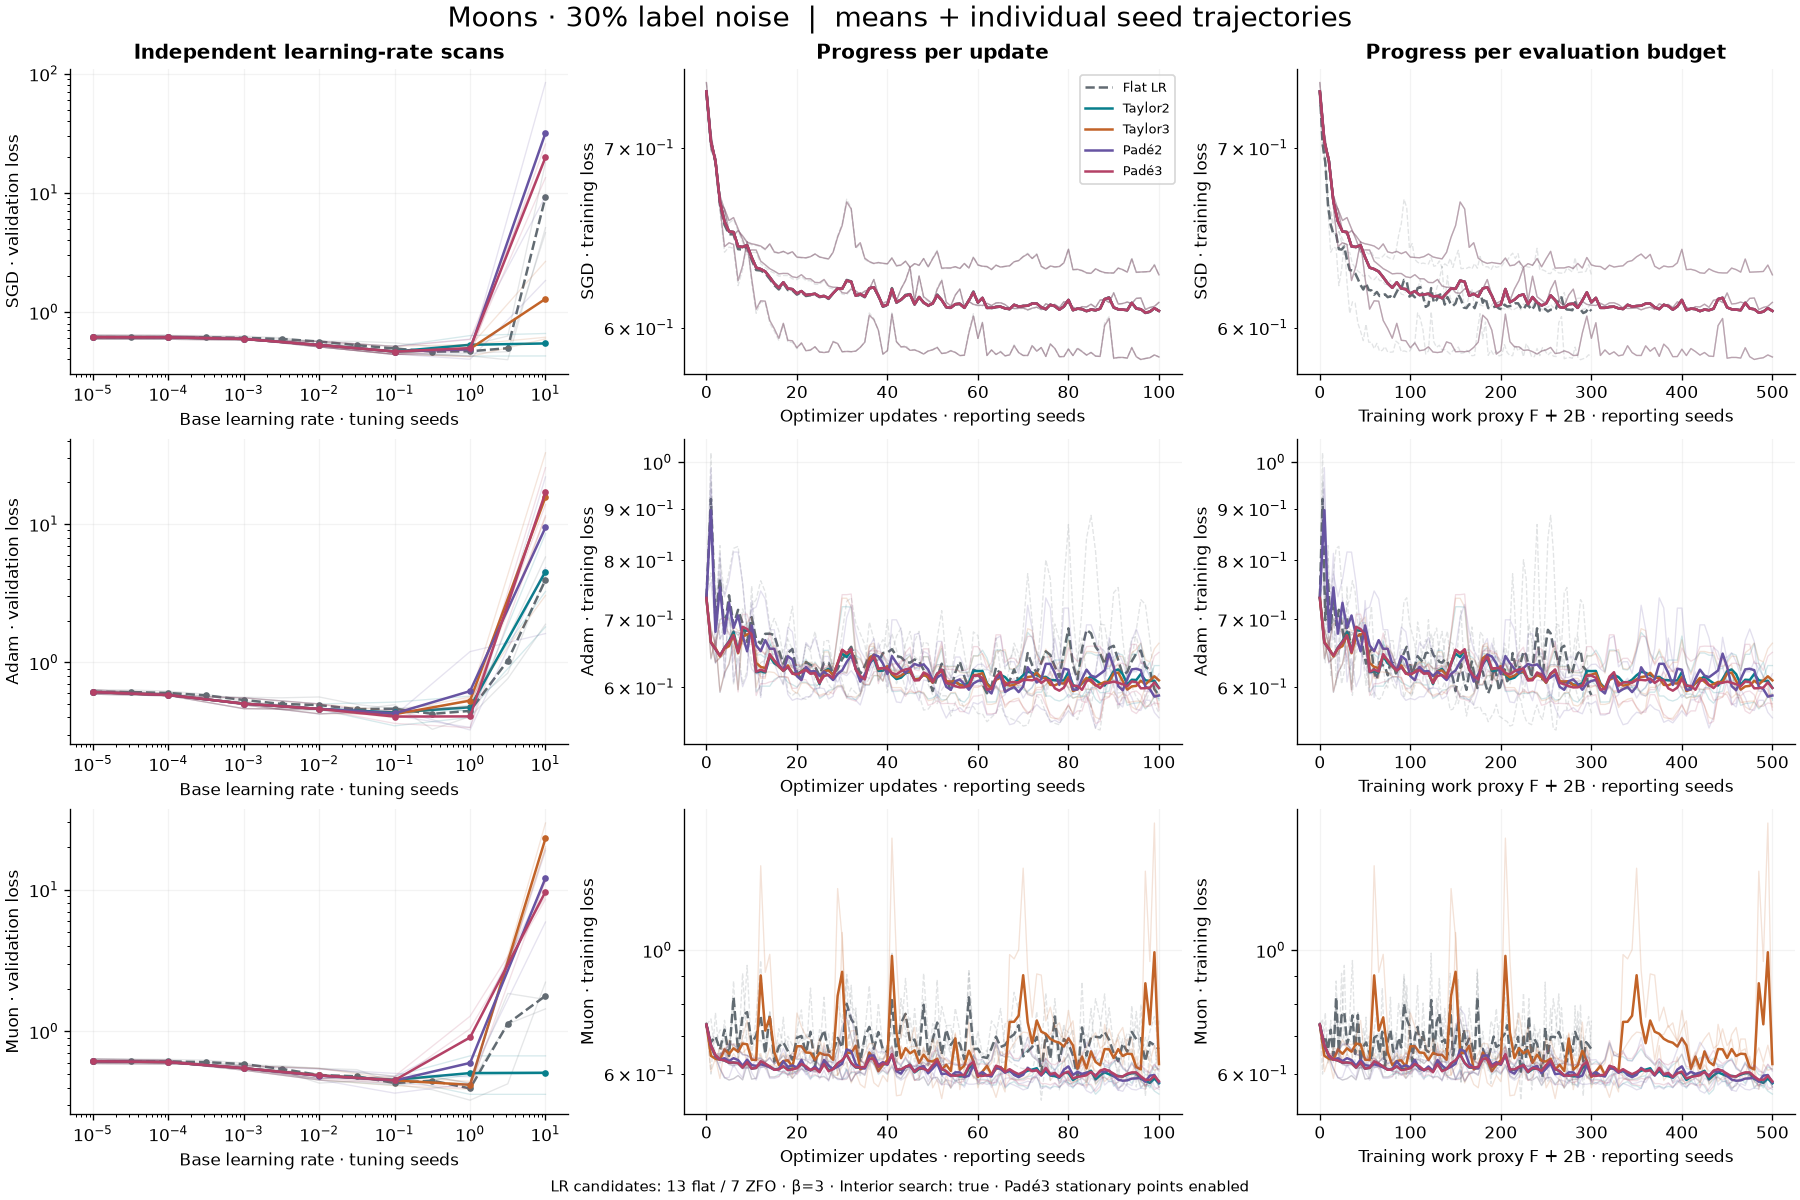

In [25]:
fig = task_figure(data, 'noisy_labels')
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=120)
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Where does each variant help, tie, or hurt?

Every ZFO/base pairing remains in this table. Counts compare the reporting seeds
pairwise against the corresponding flat optimizer. A tie is within 1% of flat
loss plus 1e-8. Nonfinite pairs are separate. These are descriptive counts, not
significance tests; no best variant is selected on these reporting results.

In [26]:
comparisons = comparison_table(data)
with __import__('pandas').option_context('display.max_rows', 160):
    display(comparisons)

,Task,Base,ZFO,Better / tied / worse,Nonfinite pairs,Paired Δ loss ± SD
0,Isotropic quadratic,SGD,Taylor2,0 / 3 / 0,0,9.07e-16 ± 1.3e-15
1,Isotropic quadratic,SGD,Taylor3,0 / 3 / 0,0,1.121e-39 ± 9.7e-40
2,Isotropic quadratic,SGD,Padé2,0 / 3 / 0,0,2.974e-13 ± 4.4e-14
3,Isotropic quadratic,SGD,Padé3,0 / 3 / 0,0,2.974e-13 ± 4.4e-14
4,Isotropic quadratic,Adam,Taylor2,3 / 0 / 0,0,-0.0001537 ± 0.00013
5,Isotropic quadratic,Adam,Taylor3,3 / 0 / 0,0,-0.0001537 ± 0.00013
6,Isotropic quadratic,Adam,Padé2,2 / 0 / 1,0,-7.886e-05 ± 0.00015
7,Isotropic quadratic,Adam,Padé3,3 / 0 / 0,0,-0.0001284 ± 0.00013
8,Isotropic quadratic,Muon,Taylor2,3 / 0 / 0,0,-0.06613 ± 0.094
9,Isotropic quadratic,Muon,Taylor3,3 / 0 / 0,0,-0.06613 ± 0.094


## Reproduction and next experiments

The saved manifest identifies the exact source hashes, software environment,
budgets, and seeds. Preserve it with `scans.csv`, `selected.csv`, `runs.csv`, and
`curves.csv`. A complete rerun never silently overwrites an earlier directory.

Useful follow-ups are five-seed reporting, longer horizons, refined/wider LR
grids for boundary selections, separately tuned compute-matched budgets, and
predeclared epsilon/beta/interior-search ablations. These extensions are not
presented as already completed results. Probe cancellation in float32 and the
memory overhead of state snapshots also need workload-specific evaluation
before moving this reference adapter to large-scale training.